# Enhancer–gene linking 10 — K562 enhancer specificity

Successor to `EP_linking9.ipynb`. **Enhancer breadth only**; the gene-expression axis and eQTL work remain deferred.

- Preserve mapped CRISPR pairs, `Regulated` labels, twelve model/perturbation scores and their context limits.
- Annotate the exact hg38 `chromStart:chromEnd` intervals. Some text IDs retain older-build coordinates; do not parse them for overlaps.
- Reuse all 674 tracks' existing 128-bp DNase peak calls. These are approximate calls on processed normalized coverage, not calibrated raw-read FDR.
- Track present: ≥50% of enhancer bp overlaps called bins, with exact edge-bin overlap weights.
- K562 active: ≥30% support among four plain `DNASE:K562` tracks (121, 122, 123, 625), i.e. ≥2/4. Treated and G1/G2 tracks are not untreated-anchor replicates.
- Breadth = number of the 674 tracks present. The panel counts tracks, not unique cell types.
- Split at the median among unique fully covered, K562-active benchmark enhancers **before model context filtering**. Breadth ≤ median = higher specificity; > median = lower. Keep ties together; groups need not balance pairs or positives.
- This is benchmark-relative specificity, not K562-exclusive activity. Missing and inactive elements remain separate.
- Model perturbations can include flanking bases (e.g. ±100 bp); annotation deliberately uses the nominal tested enhancer interval.
- All derived products go to `EP_linking10_cache/`. Existing dsQTL/eQTL caches and notebooks are preserved.


## 1. Load the derived cache

First build: `python code_test/run_ep_linking10.py all`. It reads existing predictions and cached DNase calls, not source DNase Zarr and not model inference. Later notebook runs are cache-only.


In [1]:
import json
import numpy as np
import pandas as pd
from IPython.display import Image, display
import ep_linking10_pipeline as p
import ep_linking10_analysis as a

pairs, enhancers, data = p.load_cache()
print('Mapped pairs:', len(pairs), 'positives:', pairs.label.sum(), 'unique enhancers:', len(enhancers))
assert len(pairs) == 10280 and pairs.label.sum() == 463
inventory = pd.read_csv(p.CACHE / 'score_inventory.tsv', sep='\t')
display(inventory)
print('Incomplete shuffle rows remain explicitly flagged; they are excluded from valid shared support.')


Mapped pairs: 10280 positives: 463 unique enhancers: 3926


,model,arm,bin_bp,window_bins,actual_window_bp,in_context,unshuffled_in_context
0,ours-borzoi,acc,32,37,1184,3950,NaN
1,ours-borzoi,shuffle,32,37,1184,3950,0.0
2,ours-borzoi,shuffle+acc,32,37,1184,3950,0.0
3,ours-enformer,acc,128,9,1152,3950,NaN
4,ours-enformer,shuffle,128,9,1152,3950,0.0
5,ours-enformer,shuffle+acc,128,9,1152,3950,0.0
6,ours-striped,acc,32,37,1184,9732,NaN
7,ours-striped,shuffle,32,37,1184,9732,0.0
8,ours-striped,shuffle+acc,32,37,1184,9732,0.0
9,Borzoi,shuffle,32,37,1184,3950,0.0


Incomplete shuffle rows remain explicitly flagged; they are excluded from valid shared support.


## 2. Reproduce EP_linking9 before adding specificity

- Same strand selection, pseudocount 0.01 and nominal ±576-bp TSS window; actual bin-rounded widths are reported above.
- Average precision, not trapezoidal PR area. Out-of-context score zeros are retained only for original full-benchmark reproduction.
- All-model common context = 1,763 pairs. The 262-kb cohort = 3,950 pairs and excludes pretrained Enformer from comparison.
- Separate perturbation arms: sequence-only models have `shuffle`; joint models additionally have `acc` and `shuffle+acc`.


In [2]:
reproduction = a.reproduce_benchmark(pairs, data)
display(reproduction.pivot(index=['model','arm'], columns='cohort', values='AP').round(4))
cohorts = a.cohort_masks(data)
assert cohorts['common']['context'].sum() == 1763
assert cohorts['reach262']['context'].sum() == 3950
assert pairs.label.to_numpy()[cohorts['reach262']['context']].sum() == 425
# Recorded EP_linking9 multi-model AP_common values (rounded to 4 decimals).
expected = [0.4951,0.4764,0.4935,0.4223,0.4062,0.4192,0.5702,0.5118,0.5723,0.5418,0.6562,0.7965]
observed = reproduction[reproduction.cohort.eq('common_context')].AP.to_numpy()
np.testing.assert_allclose(observed, expected, atol=0.000051, rtol=0)
print('All twelve common-context AP values reproduce the EP_linking9 snapshot.')


cohort                     all_rows  common_context  own_context  \
model         arm                                                  
AlphaGenome   shuffle        0.7154          0.7965       0.7410   
Borzoi        shuffle        0.4445          0.5418       0.4802   
Enformer      shuffle        0.5493          0.6562       0.6562   
ours-borzoi   acc            0.4232          0.4951       0.4570   
              shuffle        0.4006          0.4764       0.4324   
              shuffle+acc    0.4226          0.4935       0.4564   
ours-enformer acc            0.3534          0.4223       0.3810   
              shuffle        0.3378          0.4062       0.3640   
              shuffle+acc    0.3519          0.4192       0.3793   
ours-striped  acc            0.4352          0.5702       0.4395   
              shuffle        0.3574          0.5118       0.3608   
              shuffle+acc    0.4387          0.5723       0.4430   

cohort                     reach262_context  
model         arm                            
AlphaGenome   shuffle                0.7711  
Borzoi        shuffle                0.4802  
Enformer      shuffle                   NaN  
ours-borzoi   acc                    0.4570  
              shuffle                0.4324  
              shuffle+acc            0.4564  
ours-enformer acc                    0.3810  
              shuffle                0.3640  
              shuffle+acc            0.3793  
ours-striped  acc                    0.4970  
              shuffle                0.4281  
              shuffle+acc            0.5004

All twelve common-context AP values reproduce the EP_linking9 snapshot.


## 3. Enhancer annotations and threshold sensitivity

Annotation units are unique exact enhancer intervals. The reference population is unchanged across model cohorts. Presence at missing features has a zero storage placeholder; always apply mapping status. Fractional and center-bin readouts remain cached for fast sensitivity checks.


In [3]:
manifest = json.loads((p.CACHE / 'enhancer_manifest.json').read_text())
display(pd.Series({key:manifest[key] for key in ['anchor_indices','anchor_needed','n_tracks','median','n_reference','reference']}))
display(enhancers.groupby(['mapping_status','specificity'], dropna=False).size().to_frame('unique enhancers'))
display(a.sensitivity(enhancers))
print('Sensitivity settings are fixed annotation checks; no AP-based threshold selection.')


anchor_indices                                 [121, 122, 123, 625]
anchor_needed                                                     2
n_tracks                                                        674
median                                                        270.0
n_reference                                                    3749
reference         unique covered K562-active enhancers in mapped...
dtype: object

unique enhancers
mapping_status specificity                  
covered        higher                   1884
               inactive                  177
               lower                    1865

,setting,median,higher,lower,inactive
0,primary,270.0,1884,1865,177
1,presence_25pct,381.0,1917,1916,93
2,presence_75pct,158.0,1732,1720,474
3,center_bin,317.0,1922,1919,85
4,including_altered_K562,271.0,1870,1852,204


Sensitivity settings are fixed annotation checks; no AP-based threshold selection.


## 4. Dependence, eligibility and stratified performance

- Connected components join pairs sharing a target gene or overlapping enhancer intervals, using all mapped pairs before filtering.
- 400 bootstrap draws resample these components jointly across model arms **and specificity groups**. Shared genes across groups are not treated as independent.
- Inspect component sizes: few large components reduce information. Arbitrary distal LD and dependence by experimental study are not modeled.
- AP/AUROC are undefined with only one class. Intervals require ≥2 represented components and valid two-class bootstrap draws; valid-draw counts are exported.
- Diagnostic groups include the supported baseline, annotation-eligible baseline, higher/lower specificity, inactive and missing elements. Inactive/missing metrics are descriptive only.


In [4]:
annotated_pairs, metrics, counts, draws = a.evaluate(pairs, data, n_boot=400, seed=42)
display(counts[['cohort','stratum','n','positives','prevalence','n_enhancers','n_genes',
                'n_components','positive_enhancers','positive_genes','positive_components']].round(4))
components = pd.read_csv(p.CACHE / 'dependency_components.tsv', sep='\t')
display(components.sort_values('n_pairs', ascending=False).head(10))
print('Largest component fraction of mapped pairs:', components.n_pairs.max() / len(pairs))


10:45:50 Evaluated common with 1763 pairs and 344 dependency components


10:45:52 Evaluated reach262 with 3950 pairs and 468 dependency components


,cohort,stratum,n,positives,prevalence,n_enhancers,n_genes,n_components,positive_enhancers,positive_genes,positive_components
0,mapped,all,10280,463,0.0450,3926,2084,656,413,313,219
1,common,context_before_validity,1763,382,0.2167,1205,699,344,352,252,190
2,common,supported,1763,382,0.2167,1205,699,344,352,252,190
3,common,eligible,1725,382,0.2214,1175,693,342,352,252,190
4,common,higher,723,217,0.3001,555,411,241,205,159,136
5,common,lower,1002,165,0.1647,620,420,184,147,115,85
6,common,inactive,38,0,0.0000,30,21,10,0,0,0
7,common,missing,0,0,NaN,0,0,0,0,0,0
8,reach262,context_before_validity,3950,425,0.1076,2127,1184,468,389,283,211
9,reach262,supported,3950,425,0.1076,2127,1184,468,389,283,211


,component,n_pairs,n_genes,n_enhancers,positives
200,200,980,43,106,19
650,650,877,18,236,22
210,210,785,14,141,8
44,44,688,37,310,28
390,390,675,8,151,5
78,78,471,29,119,6
46,46,284,63,47,8
216,216,243,58,38,7
579,579,235,10,134,0
584,584,234,9,153,4


Largest component fraction of mapped pairs: 0.09533073929961089


In [5]:
for cohort in cohorts:
    print(cohort)
    table = metrics[(metrics.cohort==cohort) & metrics.stratum.isin(['higher','lower'])]
    display(table.pivot(index=['model','arm'], columns='stratum', values=['AP','AUROC','AP_ci_low','AP_ci_high']).round(4))


common


AP           AUROC         AP_ci_low          \
stratum                    higher   lower  higher   lower    higher   lower   
model         arm                                                             
AlphaGenome   shuffle      0.8779  0.6996  0.9169  0.8685    0.8277  0.6301   
Borzoi        shuffle      0.7056  0.4309  0.8081  0.7336    0.6284  0.3415   
Enformer      shuffle      0.7709  0.5605  0.8360  0.8006    0.7083  0.4738   
ours-borzoi   acc          0.5579  0.4727  0.7405  0.7757    0.4847  0.3912   
              shuffle      0.5727  0.4168  0.7406  0.7660    0.5008  0.3450   
              shuffle+acc  0.5642  0.4649  0.7407  0.7814    0.4974  0.3868   
ours-enformer acc          0.5030  0.3777  0.7035  0.7107    0.4112  0.2966   
              shuffle      0.4930  0.3580  0.6752  0.7106    0.3941  0.2689   
              shuffle+acc  0.5003  0.3757  0.7095  0.7085    0.4139  0.2961   
ours-striped  acc          0.6753  0.4549  0.7845  0.7481    0.6040  0.3555   
              shuffle      0.6224  0.4183  0.7560  0.7105    0.5369  0.3245   
              shuffle+acc  0.6737  0.4668  0.7849  0.7606    0.6059  0.3641   

                          AP_ci_high          
stratum                       higher   lower  
model         arm                             
AlphaGenome   shuffle         0.9215  0.7840  
Borzoi        shuffle         0.7893  0.5342  
Enformer      shuffle         0.8334  0.6600  
ours-borzoi   acc             0.6533  0.5639  
              shuffle         0.6559  0.5291  
              shuffle+acc     0.6581  0.5594  
ours-enformer acc             0.6400  0.4932  
              shuffle         0.6366  0.4971  
              shuffle+acc     0.6322  0.4938  
ours-striped  acc             0.7471  0.5810  
              shuffle         0.7210  0.5516  
              shuffle+acc     0.7461  0.5848

reach262


AP           AUROC         AP_ci_low          \
stratum                    higher   lower  higher   lower    higher   lower   
model         arm                                                             
AlphaGenome   shuffle      0.8503  0.6744  0.9294  0.9008    0.8064  0.6044   
Borzoi        shuffle      0.6402  0.3765  0.8570  0.8105    0.5731  0.2882   
ours-borzoi   acc          0.5200  0.4343  0.8424  0.8509    0.4453  0.3507   
              shuffle      0.5243  0.3767  0.8323  0.8461    0.4544  0.2911   
              shuffle+acc  0.5271  0.4274  0.8470  0.8565    0.4560  0.3447   
ours-enformer acc          0.4613  0.3359  0.8160  0.7978    0.3727  0.2482   
              shuffle      0.4408  0.3222  0.7918  0.8210    0.3517  0.2280   
              shuffle+acc  0.4605  0.3350  0.8234  0.7956    0.3757  0.2466   
ours-striped  acc          0.6110  0.3707  0.8282  0.7687    0.5530  0.2866   
              shuffle      0.5393  0.3323  0.7990  0.7448    0.4598  0.2470   
              shuffle+acc  0.6106  0.3831  0.8291  0.7883    0.5540  0.3024   

                          AP_ci_high          
stratum                       higher   lower  
model         arm                             
AlphaGenome   shuffle         0.9007  0.7487  
Borzoi        shuffle         0.7168  0.4833  
ours-borzoi   acc             0.6023  0.5209  
              shuffle         0.6070  0.4813  
              shuffle+acc     0.6118  0.5166  
ours-enformer acc             0.5858  0.4603  
              shuffle         0.5655  0.4528  
              shuffle+acc     0.5813  0.4576  
ours-striped  acc             0.6888  0.4808  
              shuffle         0.6405  0.4490  
              shuffle+acc     0.6802  0.4883

## 5. Potential confounding and benchmark composition

Breadth may correlate with K562 accessibility strength, interval length or enhancer–TSS distance. Check distributions and study composition; correlations do not establish the cause of a model difference. AP depends on prevalence and candidate difficulty, so cross-stratum AP differences alone are not model–specificity interactions.

`Regulated=False` means a tested pair was labeled nonregulated; it does not mean the enhancer is inactive. Experimental power fields are retained for auditing negative composition, not used to relabel or filter pairs here.


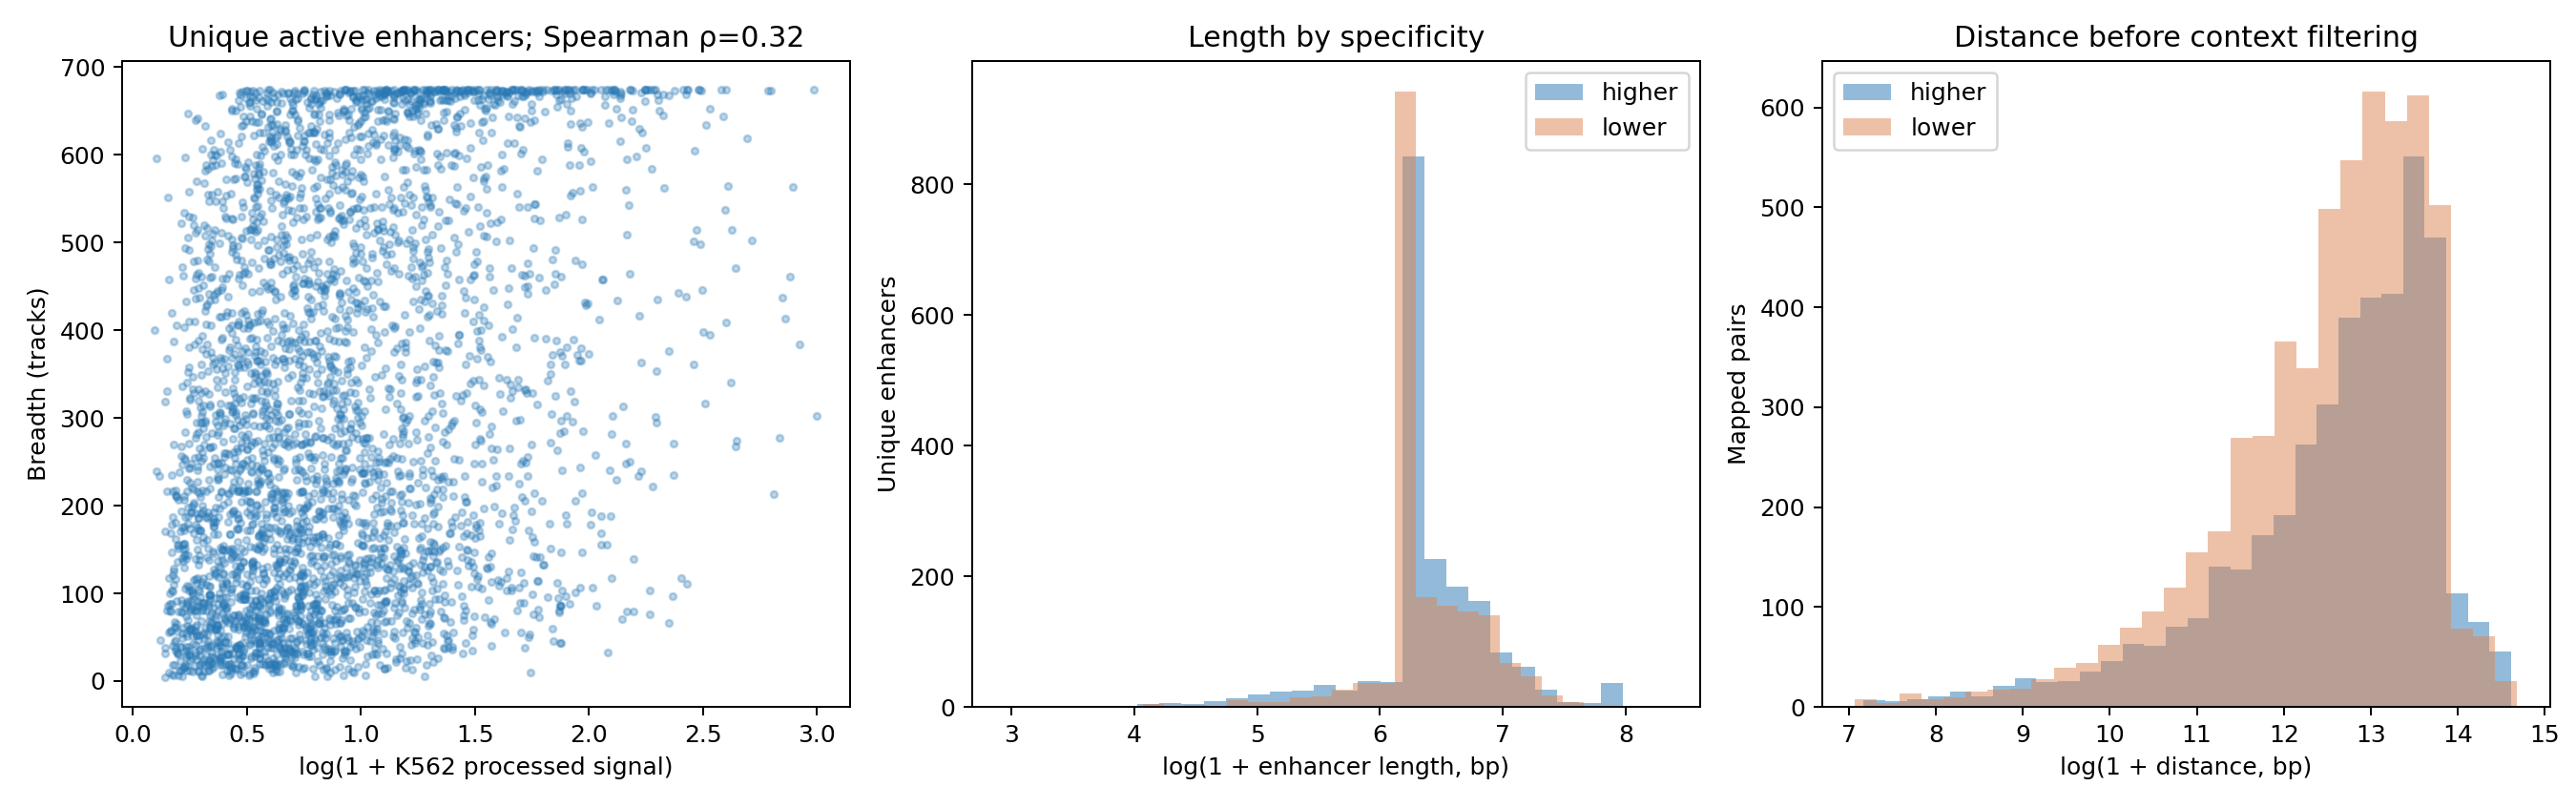

common pair-weighted diagnostics


,distance_to_TSS,enhancer_length,k562_signal_mean,breadth
specificity,,,,
higher,41548.0,520.0,1.203,111.0
inactive,67808.0,530.0,0.162,37.5
lower,46345.5,520.0,2.133,546.0


specificity,higher,inactive,lower
dataset,,,
FlowFISH_K562,213,31,444
Gasperini2019,433,6,456
TAPseq,77,1,102


,count,mean,std,min,25%,50%,75%,max
specificity,,,,,,,,
higher,506.0,0.975,0.086,0.000,0.975,1.0,1.0,1.0
inactive,38.0,0.984,0.037,0.862,1.000,1.0,1.0,1.0
lower,837.0,0.989,0.028,0.794,1.000,1.0,1.0,1.0


reach262 pair-weighted diagnostics


,distance_to_TSS,enhancer_length,k562_signal_mean,breadth
specificity,,,,
higher,107840.0,520.0,1.134,120.0
inactive,139255.0,520.0,0.152,44.0
lower,111074.0,520.0,1.945,549.5


specificity,higher,inactive,lower
dataset,,,
FlowFISH_K562,500,87,1029
Gasperini2019,860,8,982
TAPseq,204,11,269


,count,mean,std,min,25%,50%,75%,max
specificity,,,,,,,,
higher,1322.0,0.980,0.059,0.000,0.980,1.0,1.0,1.0
inactive,106.0,0.980,0.042,0.802,0.991,1.0,1.0,1.0
lower,2097.0,0.989,0.033,0.200,1.000,1.0,1.0,1.0


,cohort,stratum,distance_bin,n,positives,prevalence
0,common,higher,<=10kb,113,72,0.6372
12,common,higher,10-100kb,610,145,0.2377
24,common,higher,>100kb,0,0,NaN
36,common,lower,<=10kb,104,57,0.5481
48,common,lower,10-100kb,898,108,0.1203
60,common,lower,>100kb,0,0,NaN
72,reach262,higher,<=10kb,113,72,0.6372
83,reach262,higher,10-100kb,623,145,0.2327
94,reach262,higher,>100kb,828,25,0.0302
105,reach262,lower,<=10kb,104,57,0.5481


In [6]:
fig = a.plot_annotation_diagnostics(annotated_pairs, enhancers)
a.plt.close(fig)
display(Image(filename=str(p.CACHE / 'figures' / 'annotation_diagnostics.png')))
for cohort, cfg in cohorts.items():
    sub = annotated_pairs[cfg['support']]
    print(cohort, 'pair-weighted diagnostics')
    display(sub.groupby('specificity')[['distance_to_TSS','enhancer_length','k562_signal_mean','breadth']].median().round(3))
    display(pd.crosstab(sub.dataset, sub.specificity))
    if 'PowerAtEffectSize25' in sub:
        display(sub[sub.label.eq(0)].groupby('specificity').PowerAtEffectSize25.describe().round(3))
distance = pd.read_csv(p.CACHE / 'distance_diagnostics.tsv', sep='\t')
display(distance[['cohort','stratum','distance_bin','n','positives','prevalence']].drop_duplicates().round(4))


## 6. Paired model and perturbation-arm contrasts

- Compare `shuffle` between ours-borzoi/Borzoi, ours-enformer/Enformer, and ours-striped/Borzoi where both support the same cohort.
- Within each joint model, compare `acc` or `shuffle+acc` against `shuffle`. These answer perturbation questions, not architecture-only questions.
- `higher_minus_lower` = (AP left − AP right) in higher-specificity enhancers minus that gap in lower-specificity enhancers.
- Use shared component-bootstrap draws, including cross-stratum covariance. Intervals are descriptive, not multiplicity-adjusted hypothesis tests or causal effects. Do not infer robust superiority solely from bar heights.


In [7]:
comparisons = a.paired_comparisons(metrics, draws)
display(comparisons[comparisons.contrast.eq('higher_minus_lower')].round(4))


,cohort,left,right,contrast,delta_AP,ci_low,ci_high,valid_bootstraps,crosses_zero
2,common,ours-borzoi / shuffle,Borzoi / shuffle,higher_minus_lower,-0.1188,-0.2019,-0.0310,400,False
5,common,ours-enformer / shuffle,Enformer / shuffle,higher_minus_lower,-0.0754,-0.1967,0.0666,400,True
8,common,ours-striped / shuffle,Borzoi / shuffle,higher_minus_lower,-0.0705,-0.1931,0.0347,400,True
11,common,ours-borzoi / acc,ours-borzoi / shuffle,higher_minus_lower,-0.0707,-0.1382,0.0035,400,True
14,common,ours-borzoi / shuffle+acc,ours-borzoi / shuffle,higher_minus_lower,-0.0565,-0.1245,0.0192,400,True
17,common,ours-enformer / acc,ours-enformer / shuffle,higher_minus_lower,-0.0098,-0.0725,0.0638,400,True
20,common,ours-enformer / shuffle+acc,ours-enformer / shuffle,higher_minus_lower,-0.0104,-0.0688,0.0605,400,True
23,common,ours-striped / acc,ours-striped / shuffle,higher_minus_lower,0.0162,-0.0637,0.1172,400,True
26,common,ours-striped / shuffle+acc,ours-striped / shuffle,higher_minus_lower,0.0028,-0.0785,0.0941,400,True
29,reach262,ours-borzoi / shuffle,Borzoi / shuffle,higher_minus_lower,-0.1161,-0.1944,-0.0308,400,False


## 7. Plots — shuffle comparisons across models

Each figure compares one perturbation arm on identical supported pairs. Diagnostic plots show 95% component-bootstrap intervals and prevalence. Clean plots omit intervals/baselines, use consistent model colors, and start at 0.30 only if every displayed AP clears it.


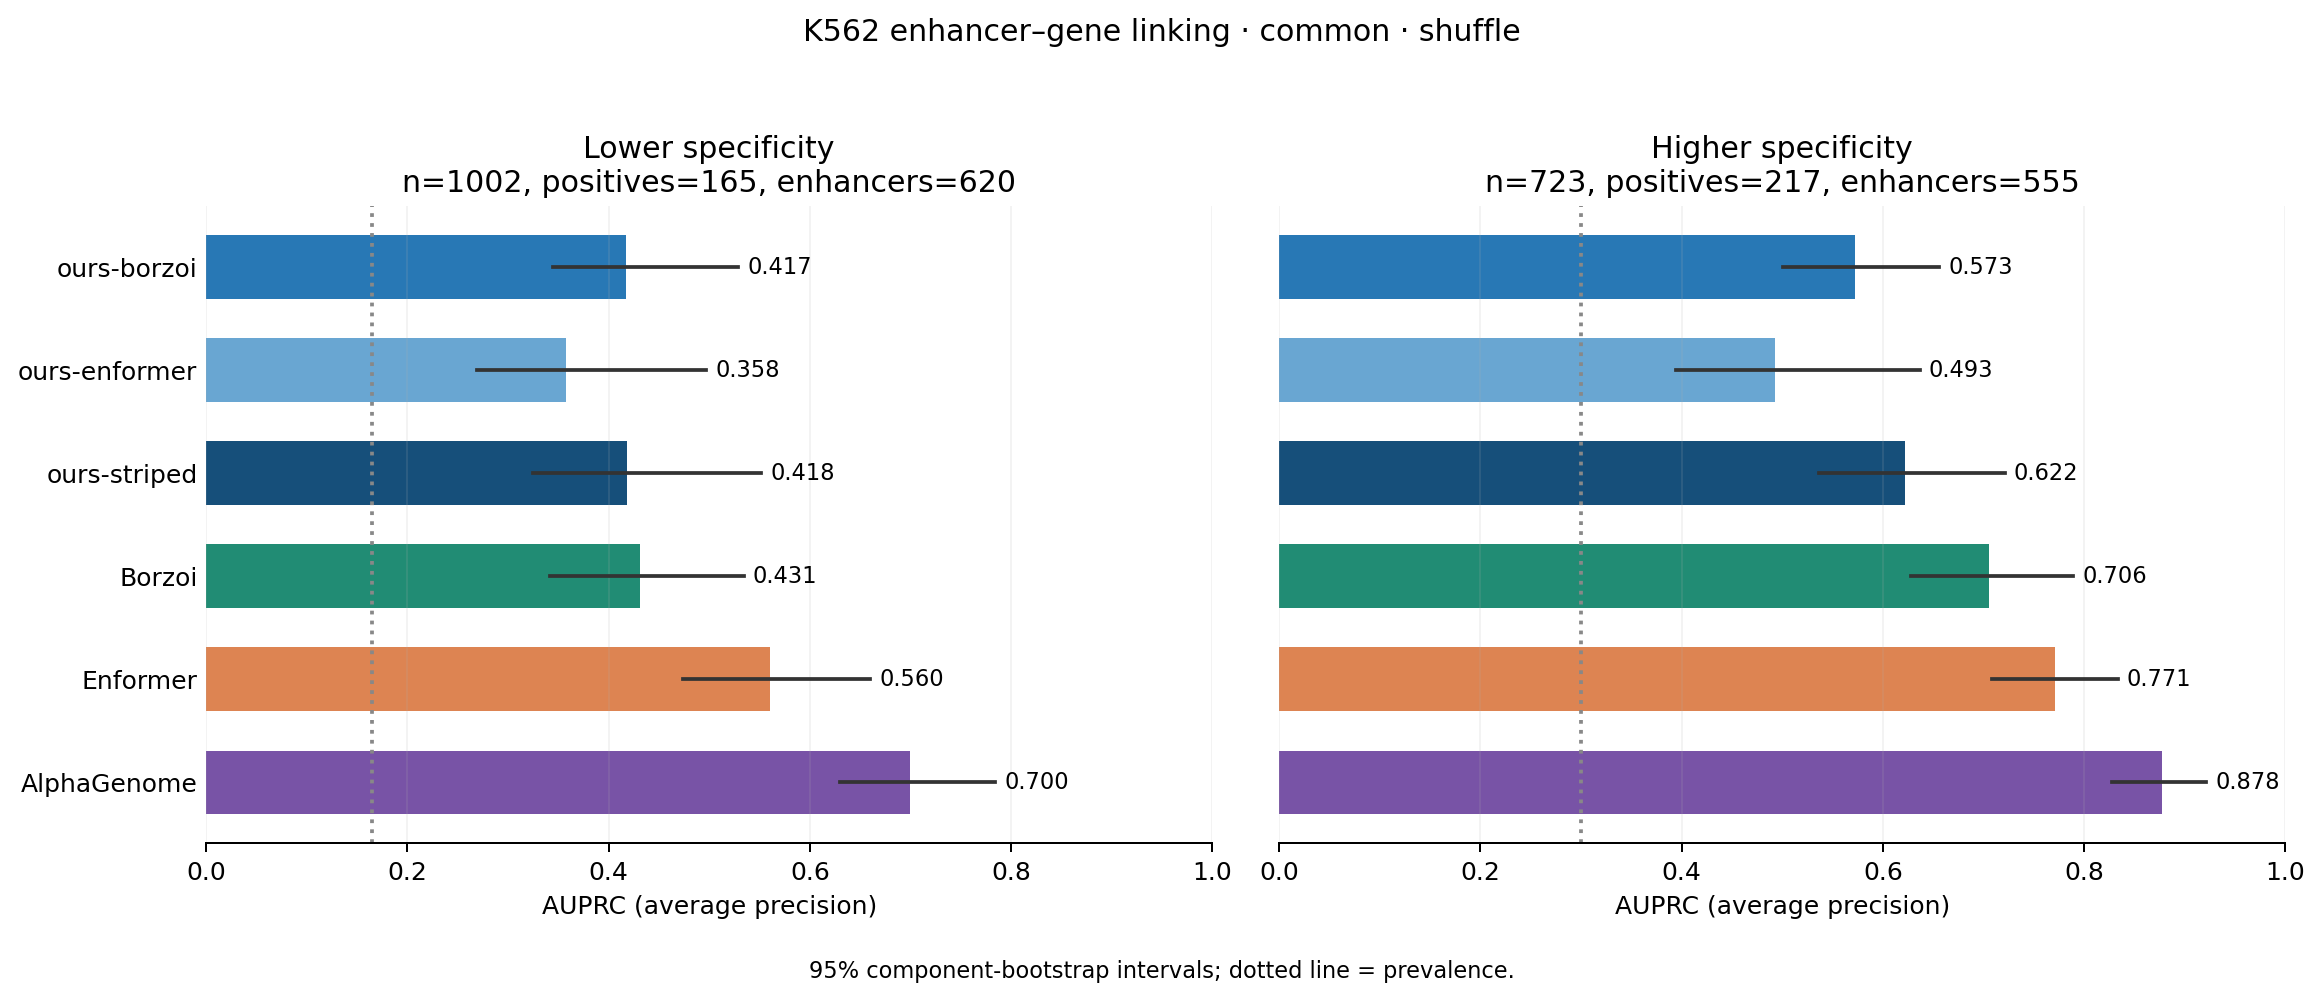

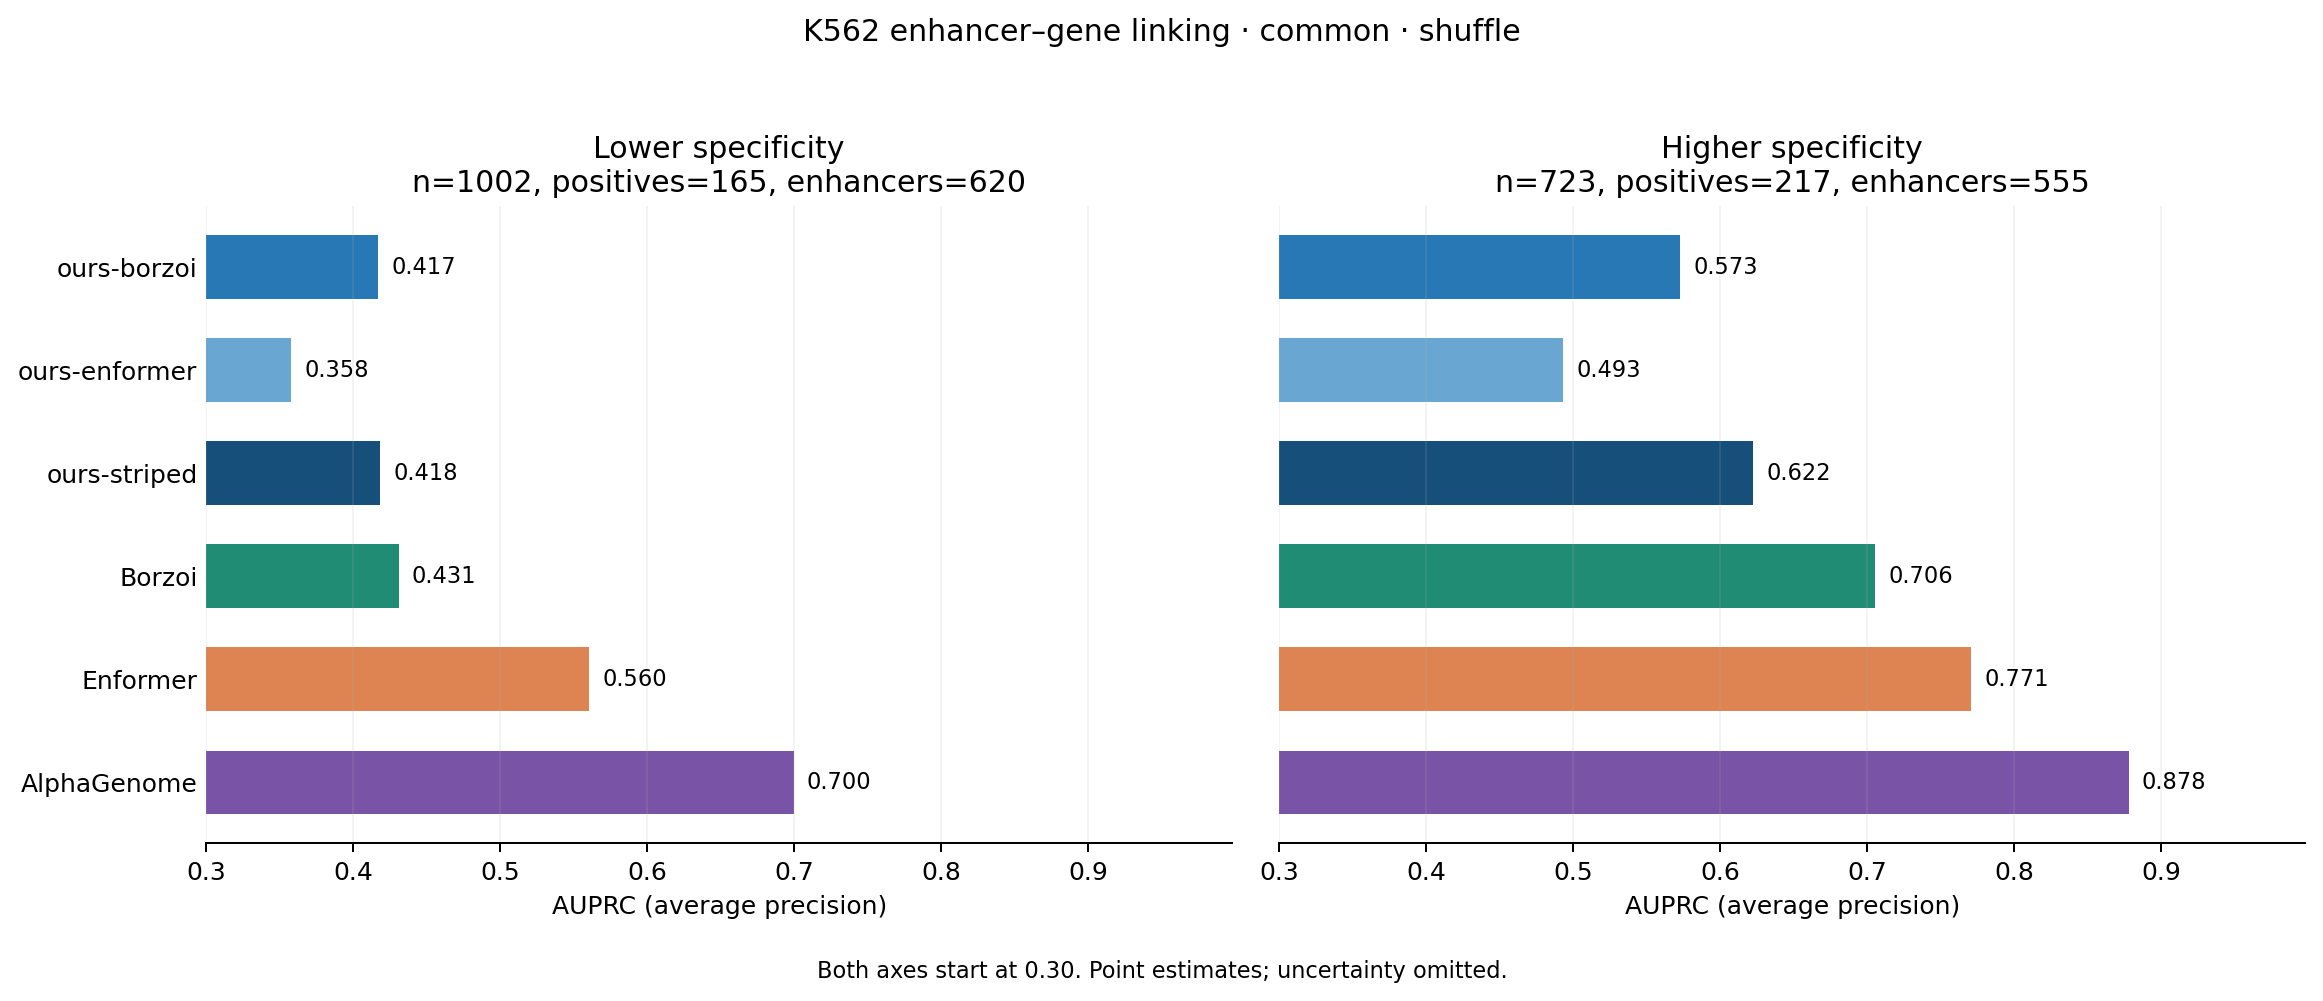

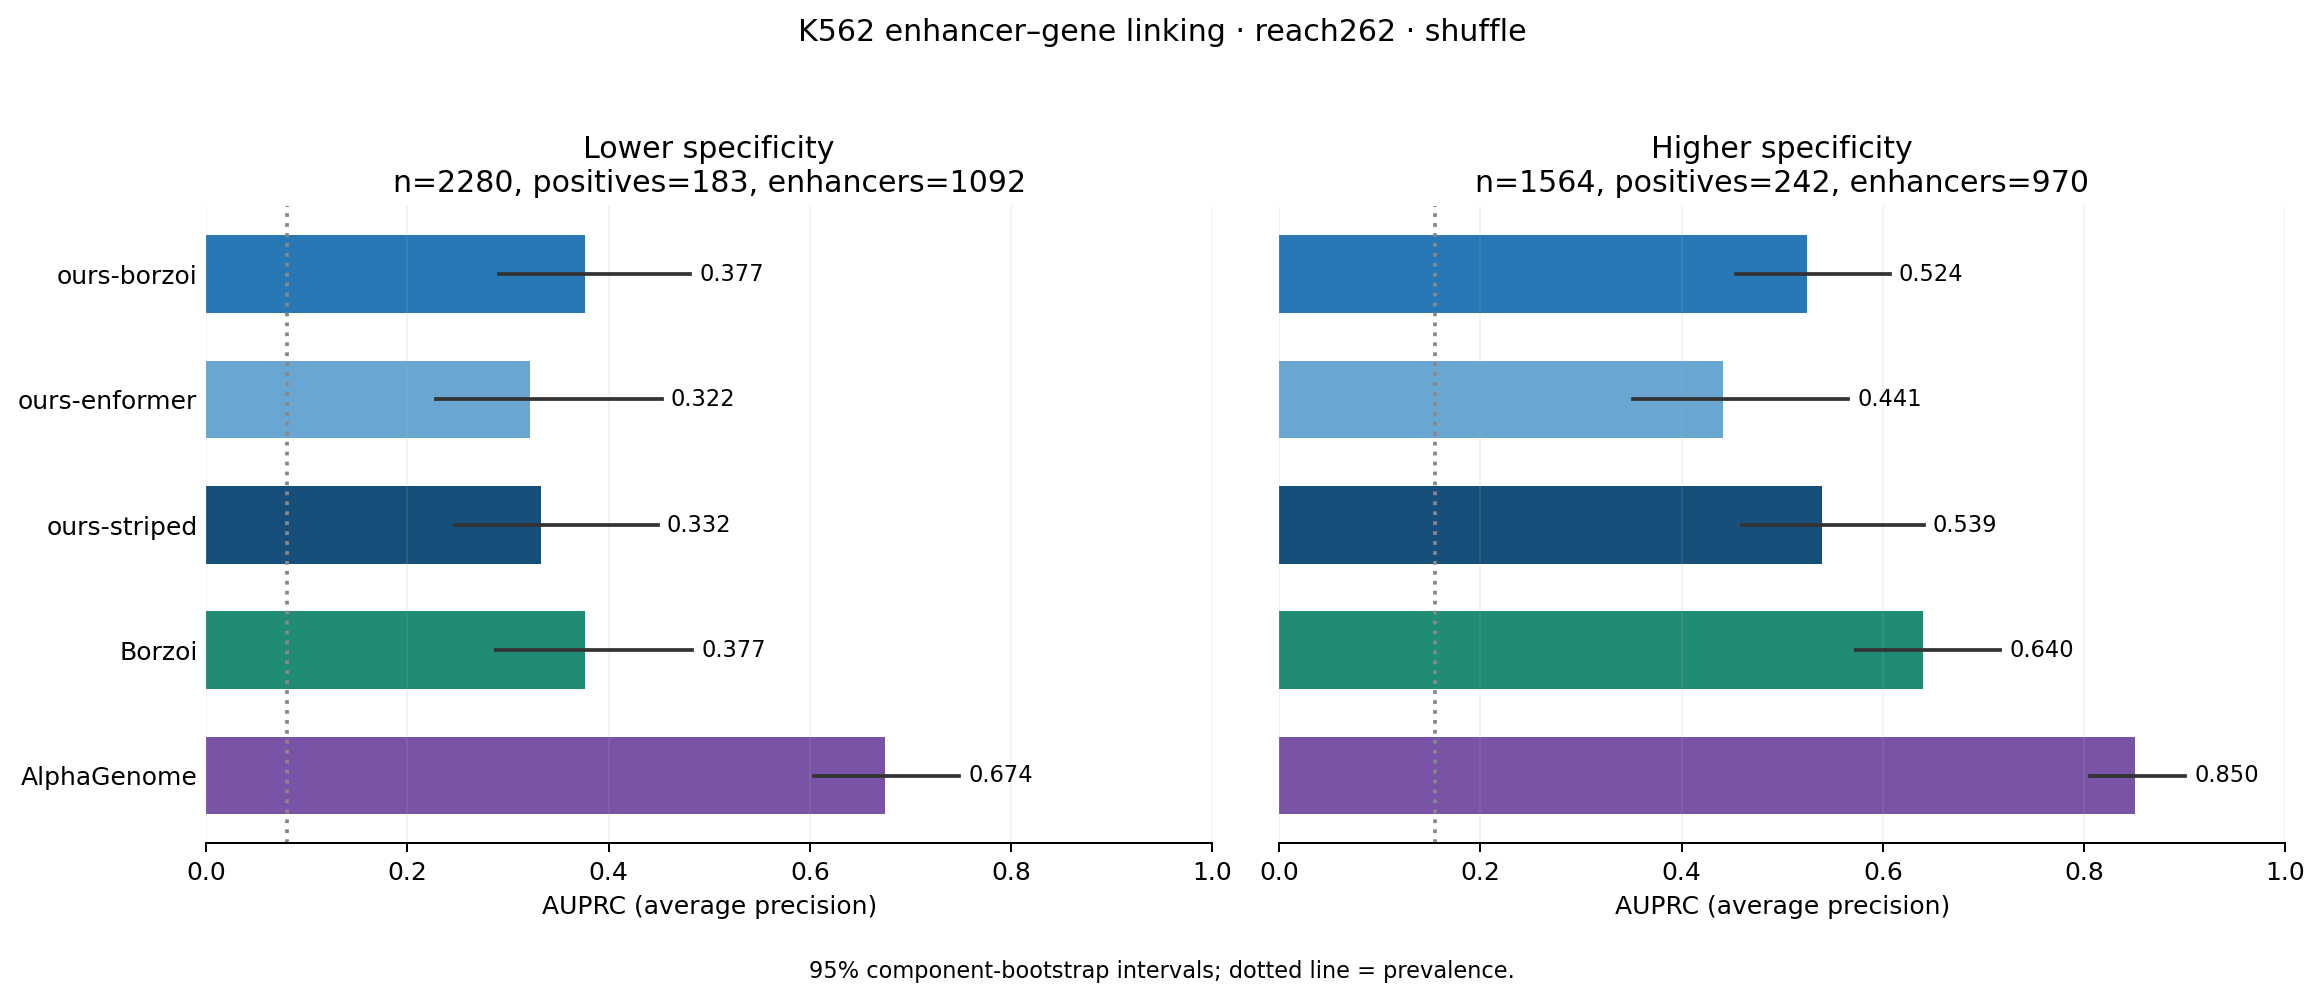

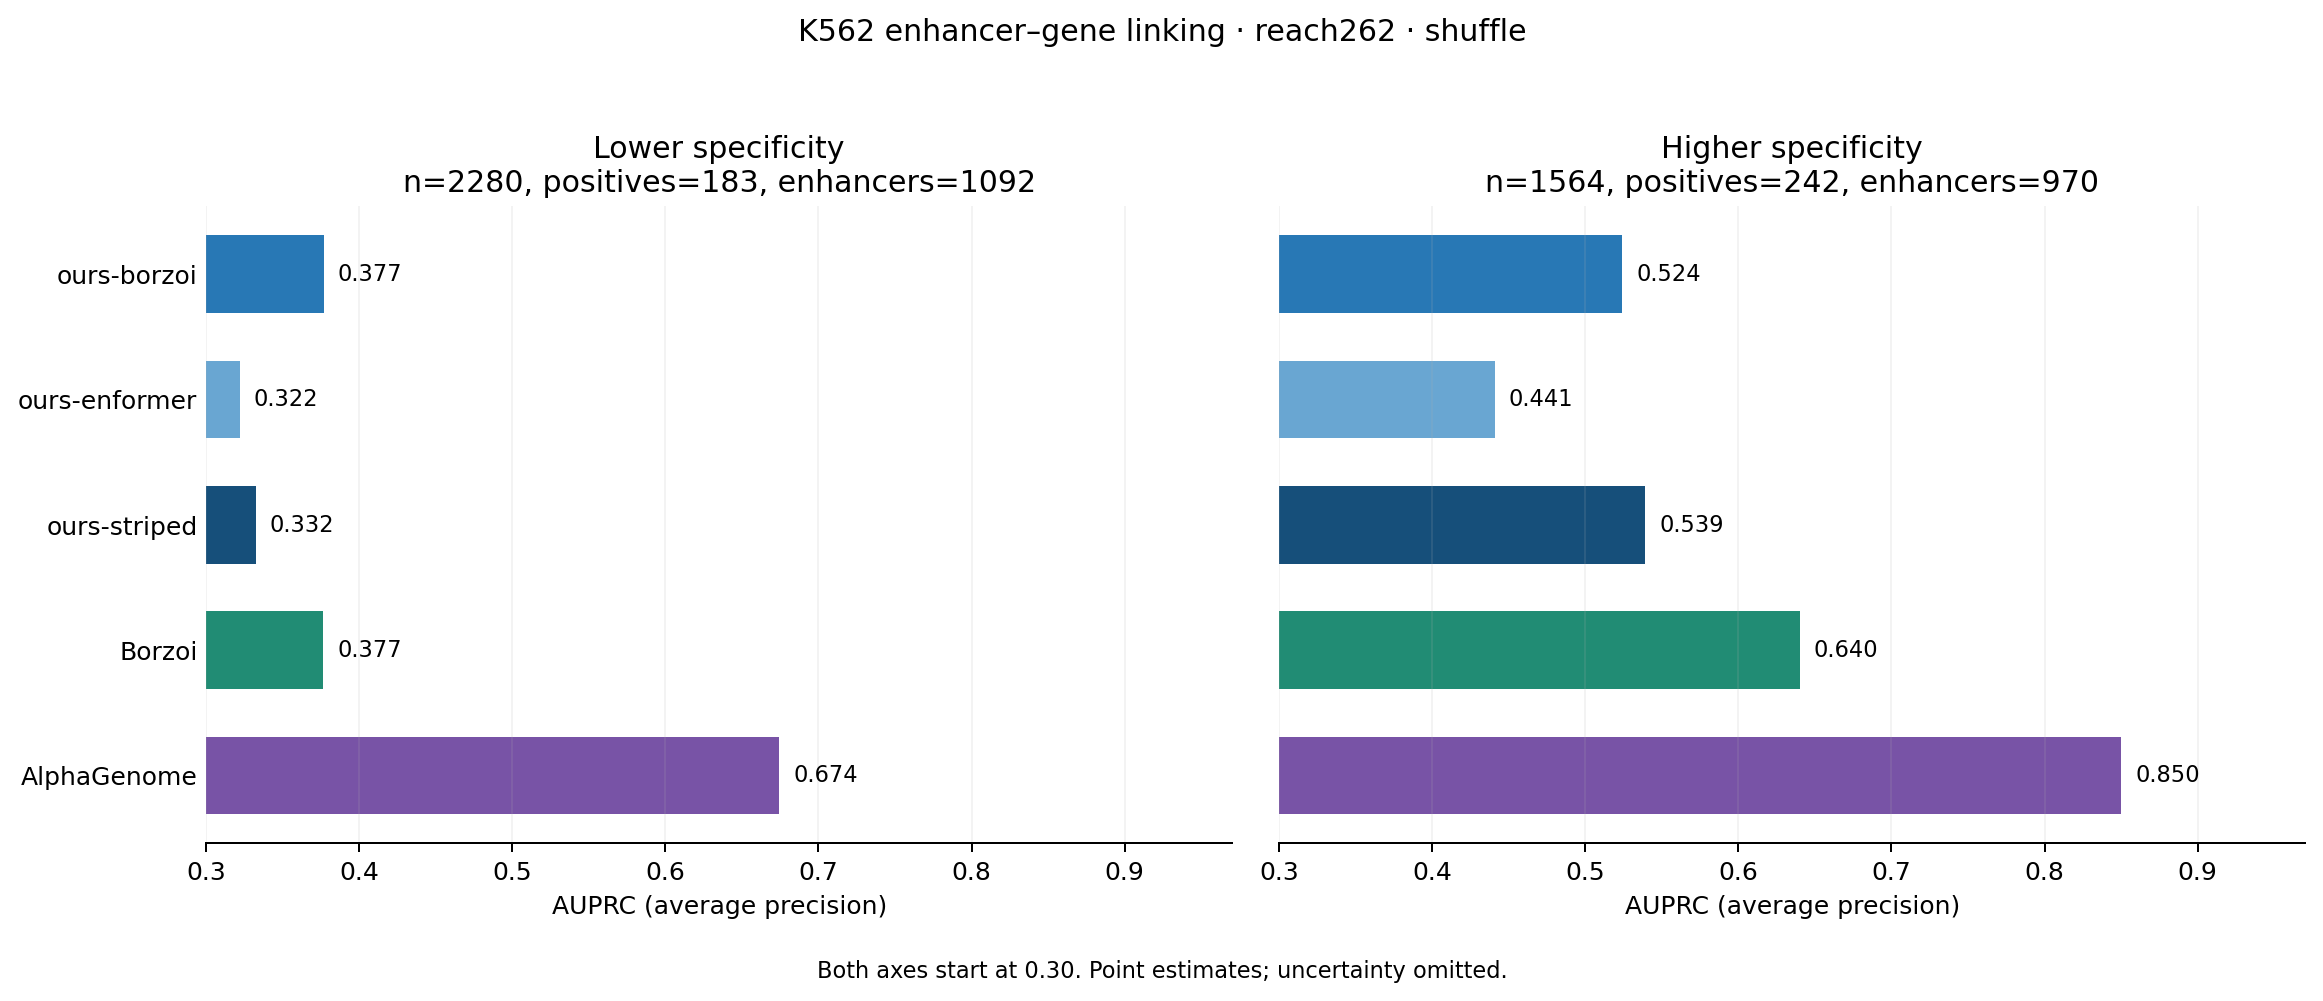

In [8]:
for cohort in cohorts:
    for diagnostic in [True, False]:
        fig = a.plot_results(metrics, cohort=cohort, arm='shuffle', diagnostic=diagnostic)
        a.plt.close(fig)
        kind = 'diagnostic' if diagnostic else 'presentation'
        display(Image(filename=str(p.CACHE / 'figures' / f'{cohort}_shuffle_{kind}.png')))


## 8. Plots — joint models' accessibility perturbations

These views keep `acc` and `shuffle+acc` separate from the sequence-only comparisons. All three joint models appear on the same cohort in each plot.


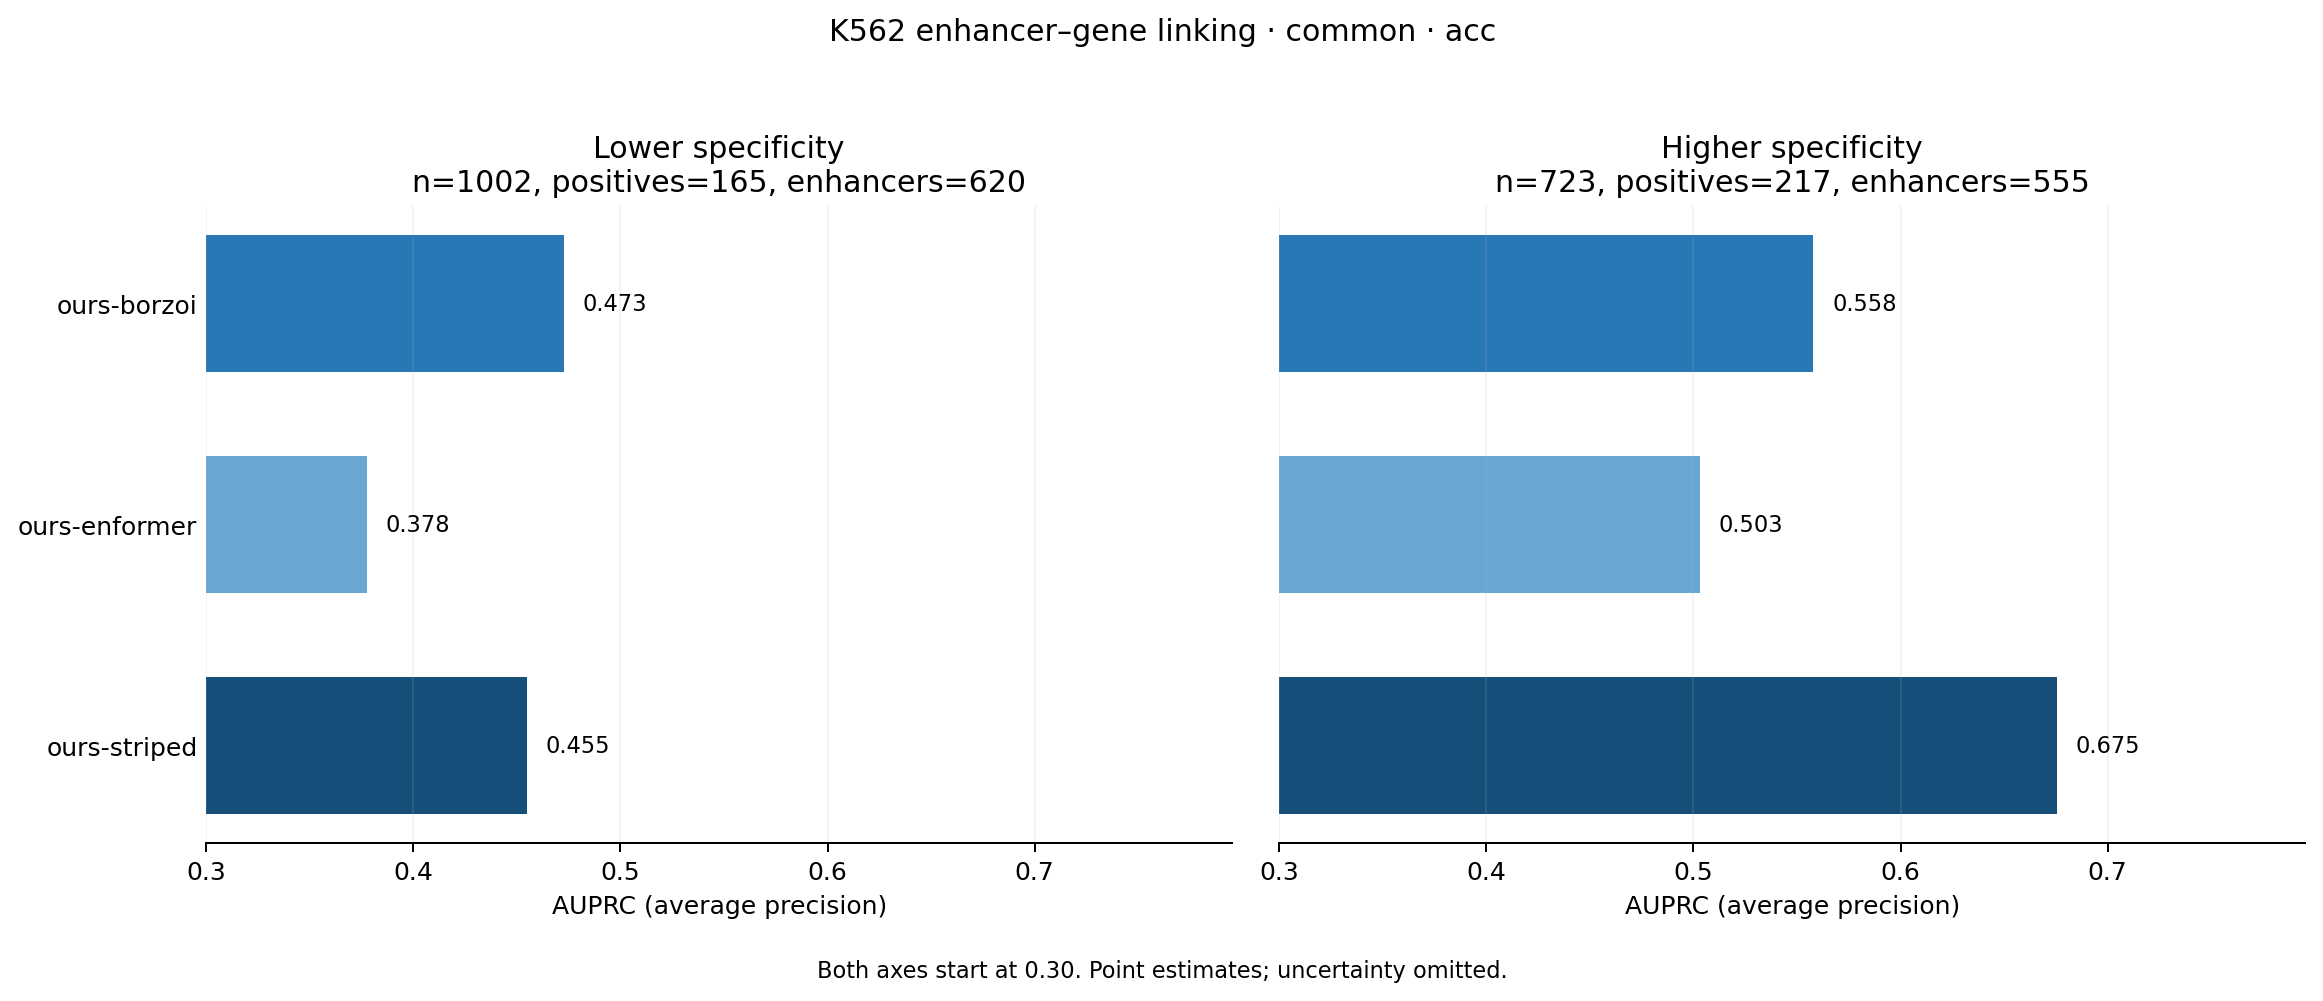

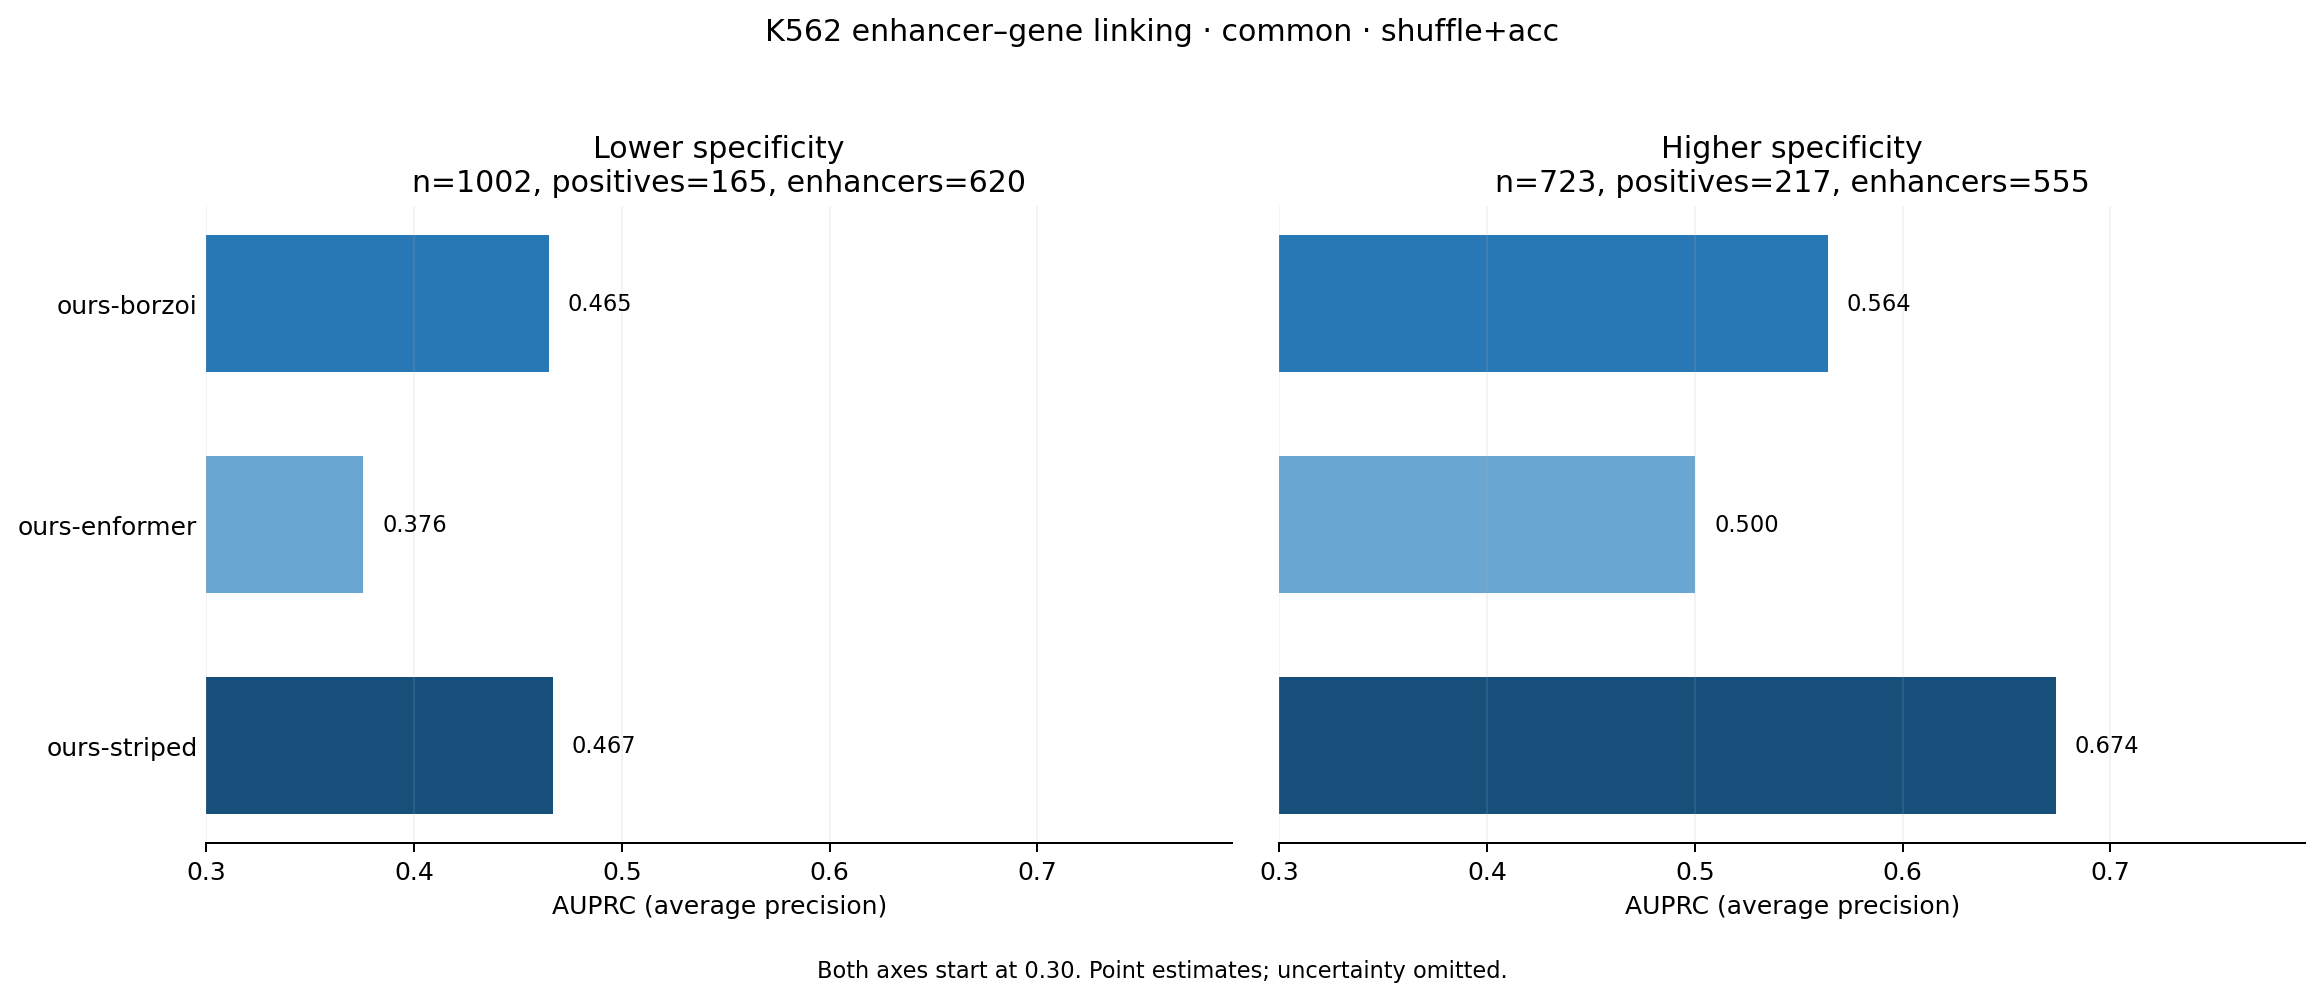

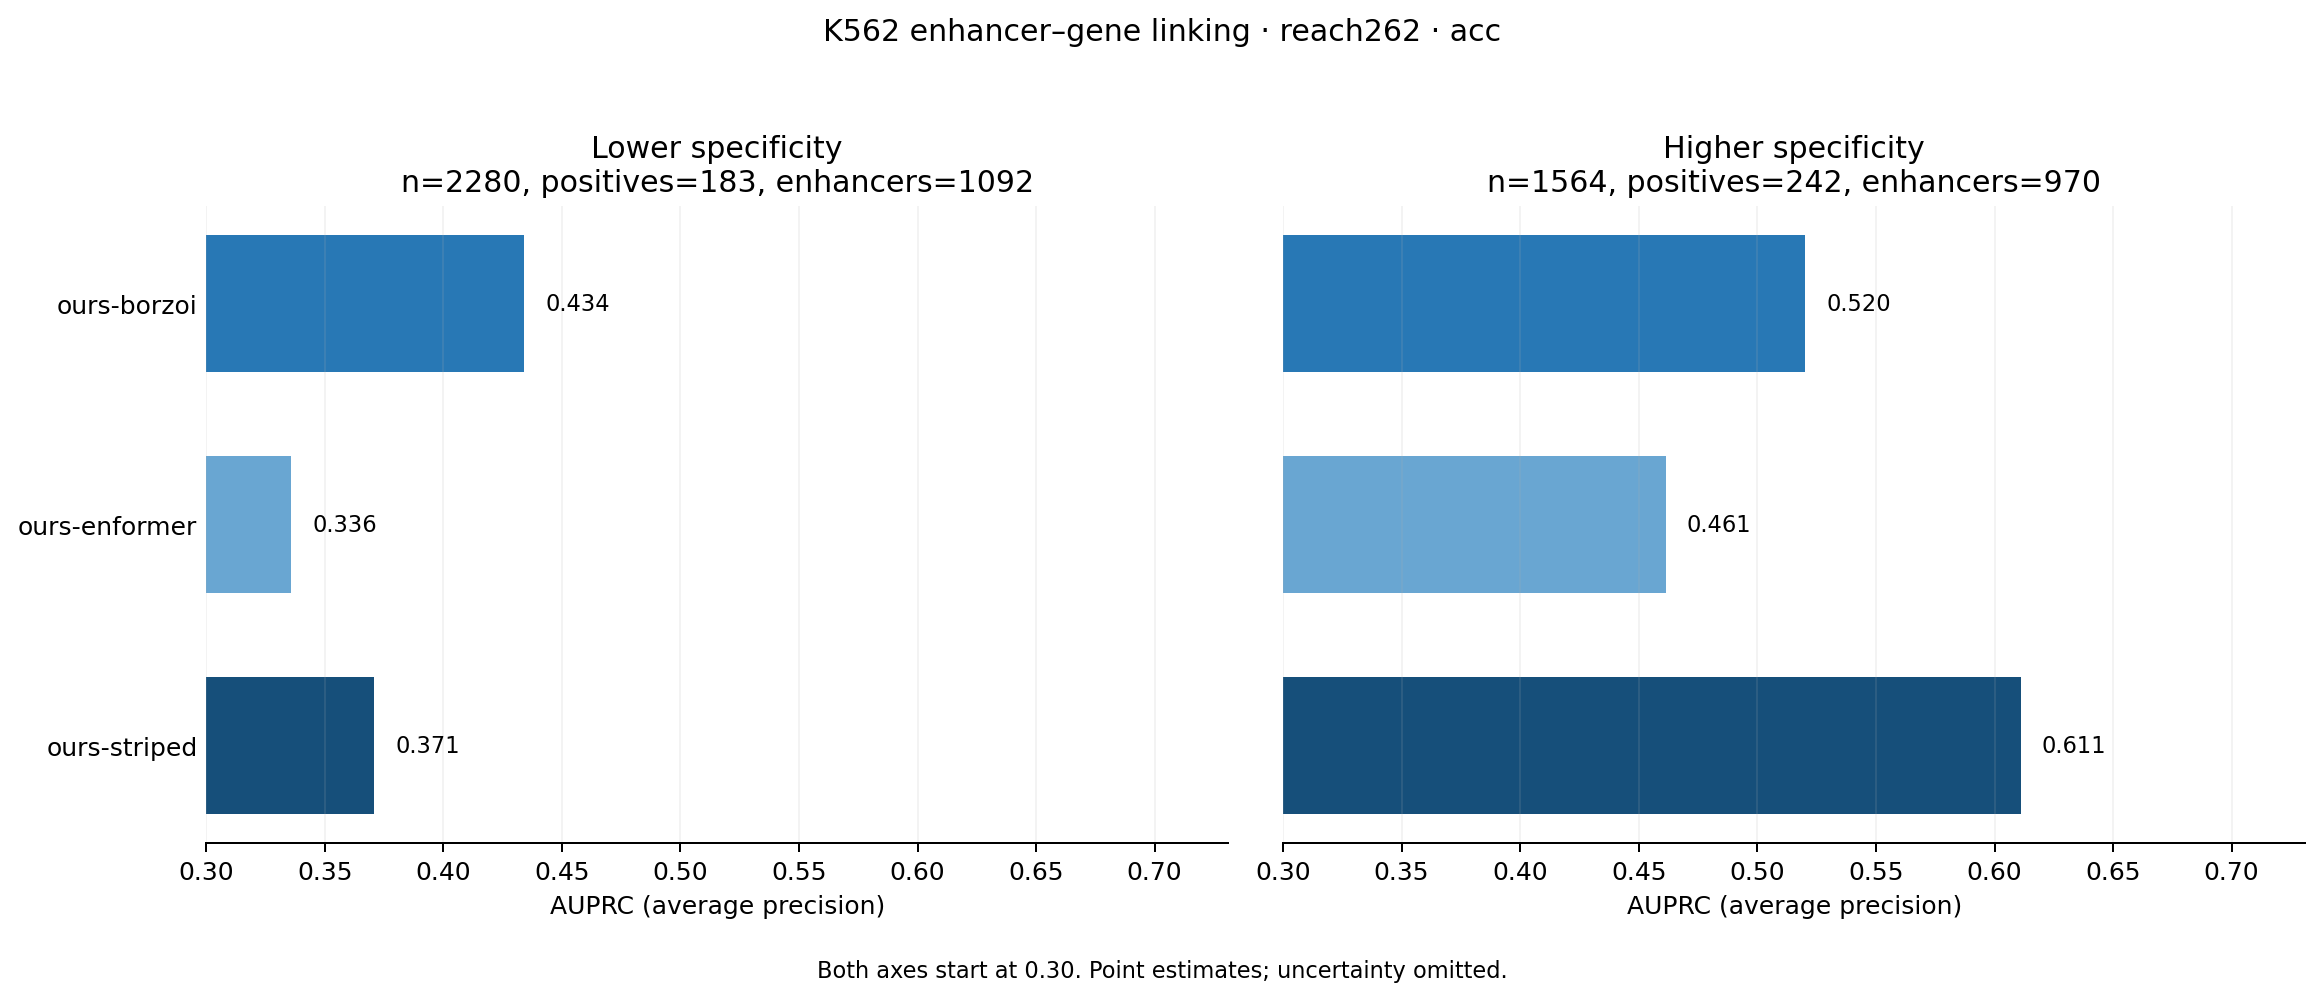

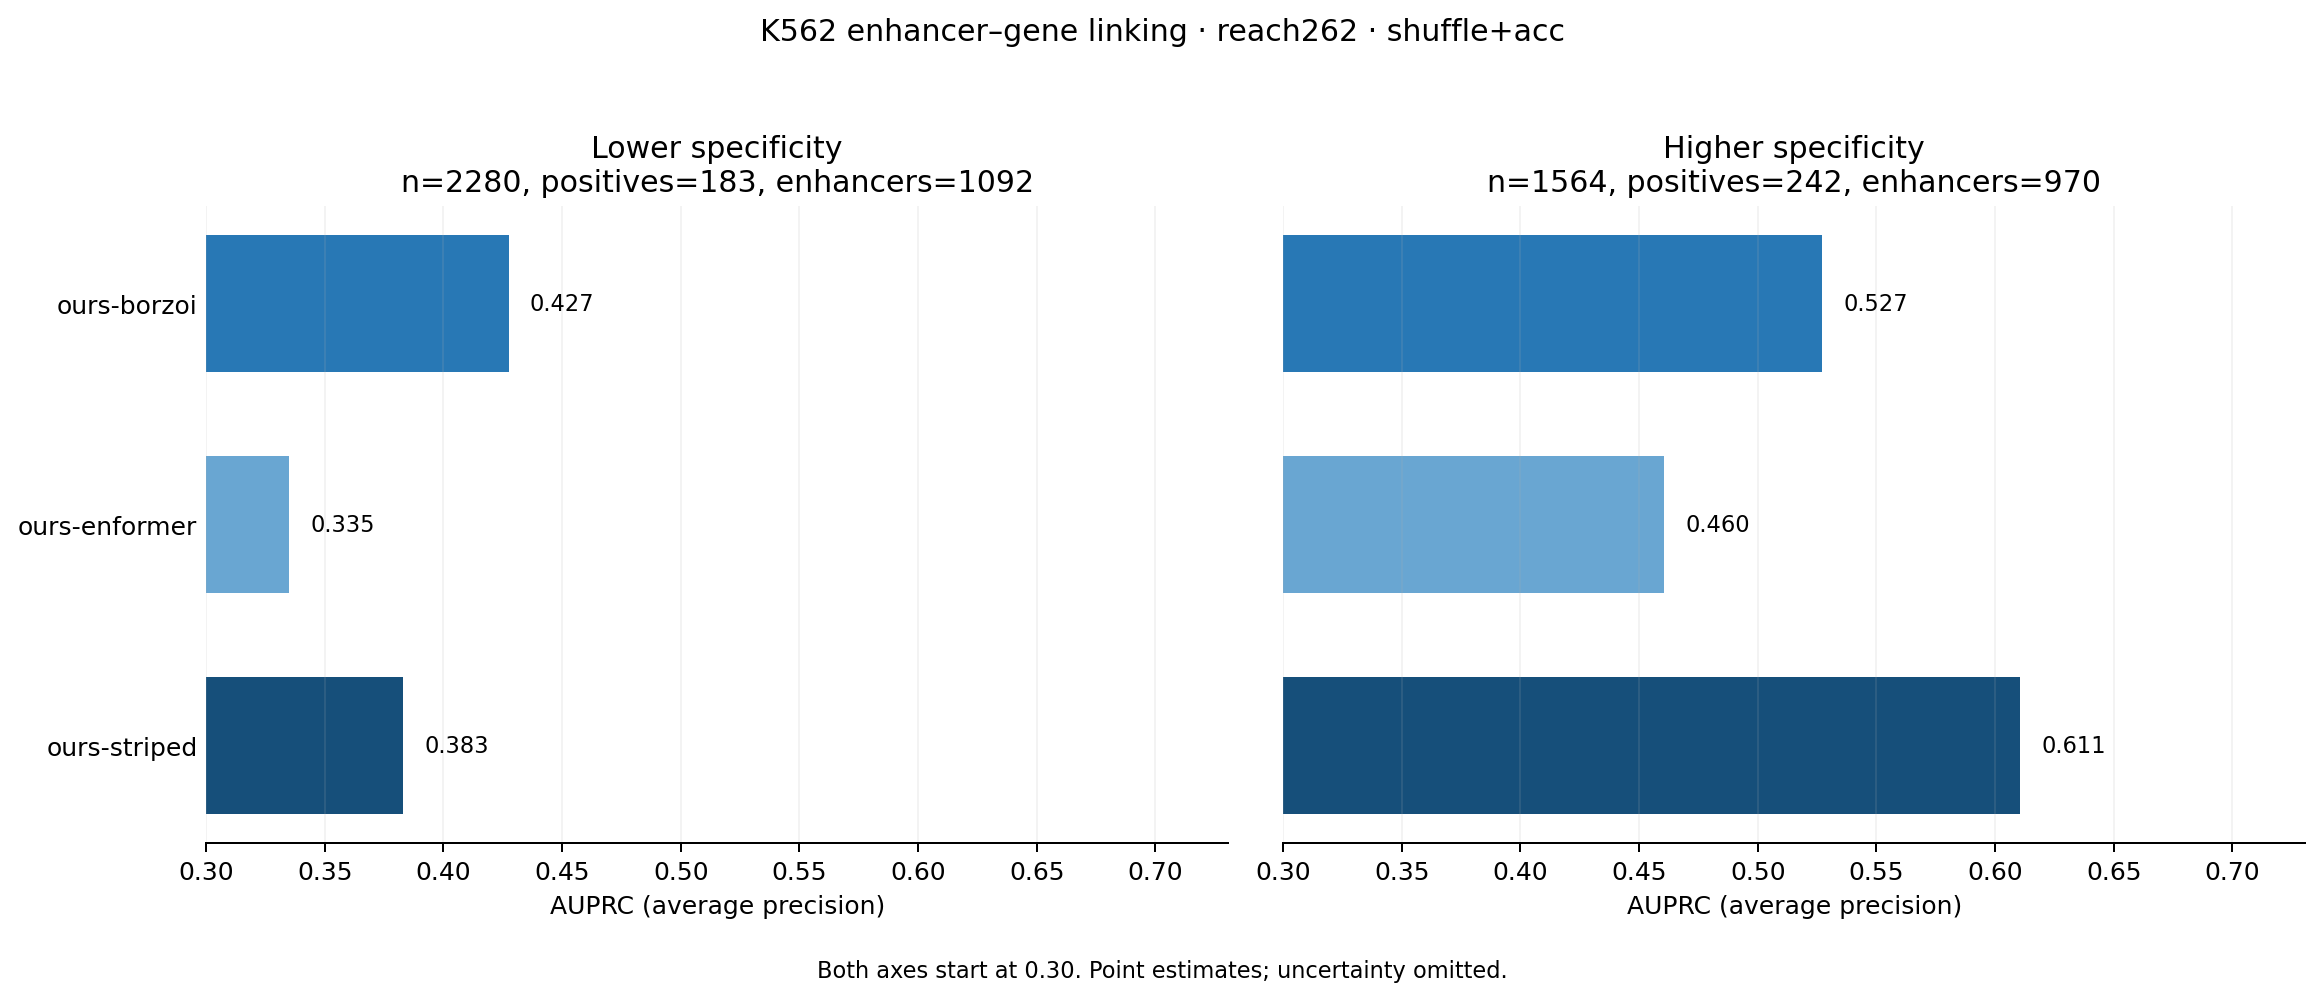

Diagnostic accessibility-arm plots also saved in figures/.


In [9]:
for cohort in cohorts:
    for arm in ['acc','shuffle+acc']:
        for diagnostic in [True, False]:
            fig = a.plot_results(metrics, cohort=cohort, arm=arm, diagnostic=diagnostic)
            a.plt.close(fig)
        display(Image(filename=str(p.CACHE / 'figures' / f'{cohort}_{arm.replace("+","_")}_presentation.png')))
print('Diagnostic accessibility-arm plots also saved in figures/.')


## 9. Conditional ranking within target gene and experimental dataset

The pooled AUPRC panels compare different candidate sets. Higher-specificity candidates have substantially greater positive prevalence, and the experimental-dataset mixture also differs. A distance-only baseline therefore obtains higher AUPRC in the higher-specificity group.

This analysis asks a narrower question: **within one target gene, experimental dataset and specificity group, does the model rank regulated candidates above nonregulated candidates?**

- An informative unit is `dataset × target gene × specificity` with at least one positive and one negative candidate.
- Compute AUROC inside each unit, then average units equally. This is a macro within-gene/dataset concordance, not pooled AUPRC.
- AUROC is equivalent to the probability that a randomly selected positive receives a higher score than a randomly selected negative, with half credit for ties.
- All candidates in a unit have the same specificity group. This avoids comparing a specific positive directly against a broad negative.
- Bootstrap the previously defined shared-gene/overlapping-enhancer components. The same component weights are used for both specificity groups and every model arm.
- Specificity groups can still contain different genes. The exact same-unit sensitivity below is cleaner but contains only 7–9 units and is too small for a strong conclusion.
- This conditions on gene and named experimental dataset. It does not adjust for all assay-design, power, distance, enhancer-strength or residual candidate-selection differences.


In [10]:
within_gene, within_gene_delta, within_gene_model, shared_unit = a.within_gene_ranking(
    annotated_pairs, data, n_boot=1000, seed=73)
for cohort in cohorts:
    print(cohort, 'macro within-gene/dataset AUROC')
    display(within_gene[(within_gene.cohort==cohort) & within_gene.arm.eq('shuffle')]
            .pivot(index='model', columns='specificity',
                   values=['macro_AUROC','ci_low','ci_high','n_gene_datasets','n_candidates','positives'])
            .round(4))


10:45:59 Within-gene ranking common : 55 informative stratum-units; 7 shared units


10:46:01 Within-gene ranking reach262 : 67 informative stratum-units; 9 shared units


common macro within-gene/dataset AUROC


macro_AUROC          ci_low         ci_high          \
specificity        higher   lower  higher   lower  higher   lower   
model                                                               
AlphaGenome        0.7615  0.8563  0.6040  0.7455  0.9072  0.9630   
Borzoi             0.7422  0.5710  0.5713  0.4111  0.8671  0.6964   
Enformer           0.8271  0.7913  0.6965  0.6780  0.9275  0.8759   
ours-borzoi        0.5722  0.7473  0.2857  0.6206  0.7615  0.8438   
ours-enformer      0.7291  0.7189  0.5576  0.5808  0.8654  0.8275   
ours-striped       0.6367  0.6243  0.4149  0.4753  0.7958  0.7692   

              n_gene_datasets       n_candidates        positives        
specificity            higher lower       higher  lower    higher lower  
model                                                                    
AlphaGenome              23.0  32.0        145.0  311.0      35.0  65.0  
Borzoi                   23.0  32.0        145.0  311.0      35.0  65.0  
Enformer                 23.0  32.0        145.0  311.0      35.0  65.0  
ours-borzoi              23.0  32.0        145.0  311.0      35.0  65.0  
ours-enformer            23.0  32.0        145.0  311.0      35.0  65.0  
ours-striped             23.0  32.0        145.0  311.0      35.0  65.0

reach262 macro within-gene/dataset AUROC


macro_AUROC          ci_low         ci_high          \
specificity        higher   lower  higher   lower  higher   lower   
model                                                               
AlphaGenome        0.7808  0.8653  0.6222  0.7615  0.8878  0.9565   
Borzoi             0.7817  0.6604  0.6299  0.4981  0.8821  0.7727   
ours-borzoi        0.6469  0.7733  0.4382  0.6285  0.7989  0.8722   
ours-enformer      0.7497  0.8035  0.5959  0.6638  0.8650  0.9028   
ours-striped       0.6664  0.6031  0.4671  0.4458  0.7950  0.7256   

              n_gene_datasets       n_candidates        positives        
specificity            higher lower       higher  lower    higher lower  
model                                                                    
AlphaGenome              30.0  37.0        302.0  682.0      46.0  73.0  
Borzoi                   30.0  37.0        302.0  682.0      46.0  73.0  
ours-borzoi              30.0  37.0        302.0  682.0      46.0  73.0  
ours-enformer            30.0  37.0        302.0  682.0      46.0  73.0  
ours-striped             30.0  37.0        302.0  682.0      46.0  73.0

### Specificity differences and focused model interactions

`higher_minus_lower` compares each model's macro AUROC between specificity groups. The focused model interaction asks whether the left-minus-right model gap changes between groups. All intervals use shared component draws. These are exploratory comparisons without multiplicity correction.


In [11]:
display(within_gene_delta[within_gene_delta.arm.eq('shuffle')].round(4))
display(within_gene_model.round(4))


,cohort,model,arm,higher_minus_lower,ci_low,ci_high,valid_bootstraps,crosses_zero
1,common,ours-borzoi,shuffle,-0.1751,-0.4762,0.0576,1000,True
4,common,ours-enformer,shuffle,0.0102,-0.1875,0.1855,1000,True
7,common,ours-striped,shuffle,0.0124,-0.2387,0.2094,1000,True
9,common,Borzoi,shuffle,0.1712,-0.0568,0.3819,1000,True
10,common,Enformer,shuffle,0.0357,-0.1184,0.1787,1000,True
11,common,AlphaGenome,shuffle,-0.0948,-0.2763,0.0895,1000,True
13,reach262,ours-borzoi,shuffle,-0.1264,-0.3412,0.0584,1000,True
16,reach262,ours-enformer,shuffle,-0.0538,-0.2195,0.1023,1000,True
19,reach262,ours-striped,shuffle,0.0634,-0.1345,0.2315,1000,True
21,reach262,Borzoi,shuffle,0.1213,-0.0627,0.2842,1000,True


,cohort,left,right,higher_gap,lower_gap,difference_of_differences,ci_low,ci_high,valid_bootstraps,crosses_zero
0,common,ours-borzoi / shuffle,Borzoi / shuffle,-0.1701,0.1763,-0.3464,-0.6673,-0.1174,1000,False
1,common,ours-enformer / shuffle,Enformer / shuffle,-0.0980,-0.0725,-0.0255,-0.2583,0.2261,1000,True
2,common,ours-striped / shuffle,Borzoi / shuffle,-0.1055,0.0533,-0.1588,-0.3947,0.0503,1000,True
3,common,ours-borzoi / acc,ours-borzoi / shuffle,0.0955,-0.0844,0.1799,-0.0327,0.5144,1000,True
4,common,ours-borzoi / shuffle+acc,ours-borzoi / shuffle,0.0489,-0.0692,0.1181,-0.0767,0.4204,1000,True
5,common,ours-enformer / acc,ours-enformer / shuffle,-0.1035,-0.0352,-0.0683,-0.3019,0.1397,1000,True
6,common,ours-enformer / shuffle+acc,ours-enformer / shuffle,-0.1089,-0.0969,-0.0120,-0.2494,0.2225,1000,True
7,common,ours-striped / acc,ours-striped / shuffle,-0.0614,0.0770,-0.1384,-0.2524,0.0121,1000,True
8,common,ours-striped / shuffle+acc,ours-striped / shuffle,-0.0490,0.0868,-0.1357,-0.2376,-0.0085,1000,False
9,reach262,ours-borzoi / shuffle,Borzoi / shuffle,-0.1348,0.1129,-0.2477,-0.5213,-0.0265,1000,False


### Exact shared-unit sensitivity

Require the same experimental dataset and target gene to be informative in both specificity groups. This isolates the group comparison further, but only 7 units survive in the all-model cohort and 9 in the 262-kb cohort. Report observed macro AUROC without inferential intervals; use it only as a direction check.


In [12]:
for cohort in cohorts:
    d=shared_unit[(shared_unit.cohort==cohort) & shared_unit.arm.eq('shuffle')]
    print(cohort, 'shared informative units:', int(d.n_shared_gene_datasets.iloc[0]))
    display(d.pivot(index='model', columns='specificity', values='macro_AUROC').round(4))


common shared informative units: 7


specificity,higher,lower
model,,
AlphaGenome,0.7644,0.8857
Borzoi,0.5541,0.6640
Enformer,0.8406,0.8895
ours-borzoi,0.6168,0.7643
ours-enformer,0.7690,0.8361
ours-striped,0.7717,0.8386


reach262 shared informative units: 9


specificity,higher,lower
model,,
AlphaGenome,0.7873,0.9313
Borzoi,0.6631,0.7659
ours-borzoi,0.5664,0.8462
ours-enformer,0.8274,0.9768
ours-striped,0.7136,0.7555


### Conditional-ranking plots

Diagnostic plots show component-bootstrap intervals and the 0.5 chance line. Clean plots preserve the requested lower-specificity-left / higher-specificity-right layout and omit uncertainty.


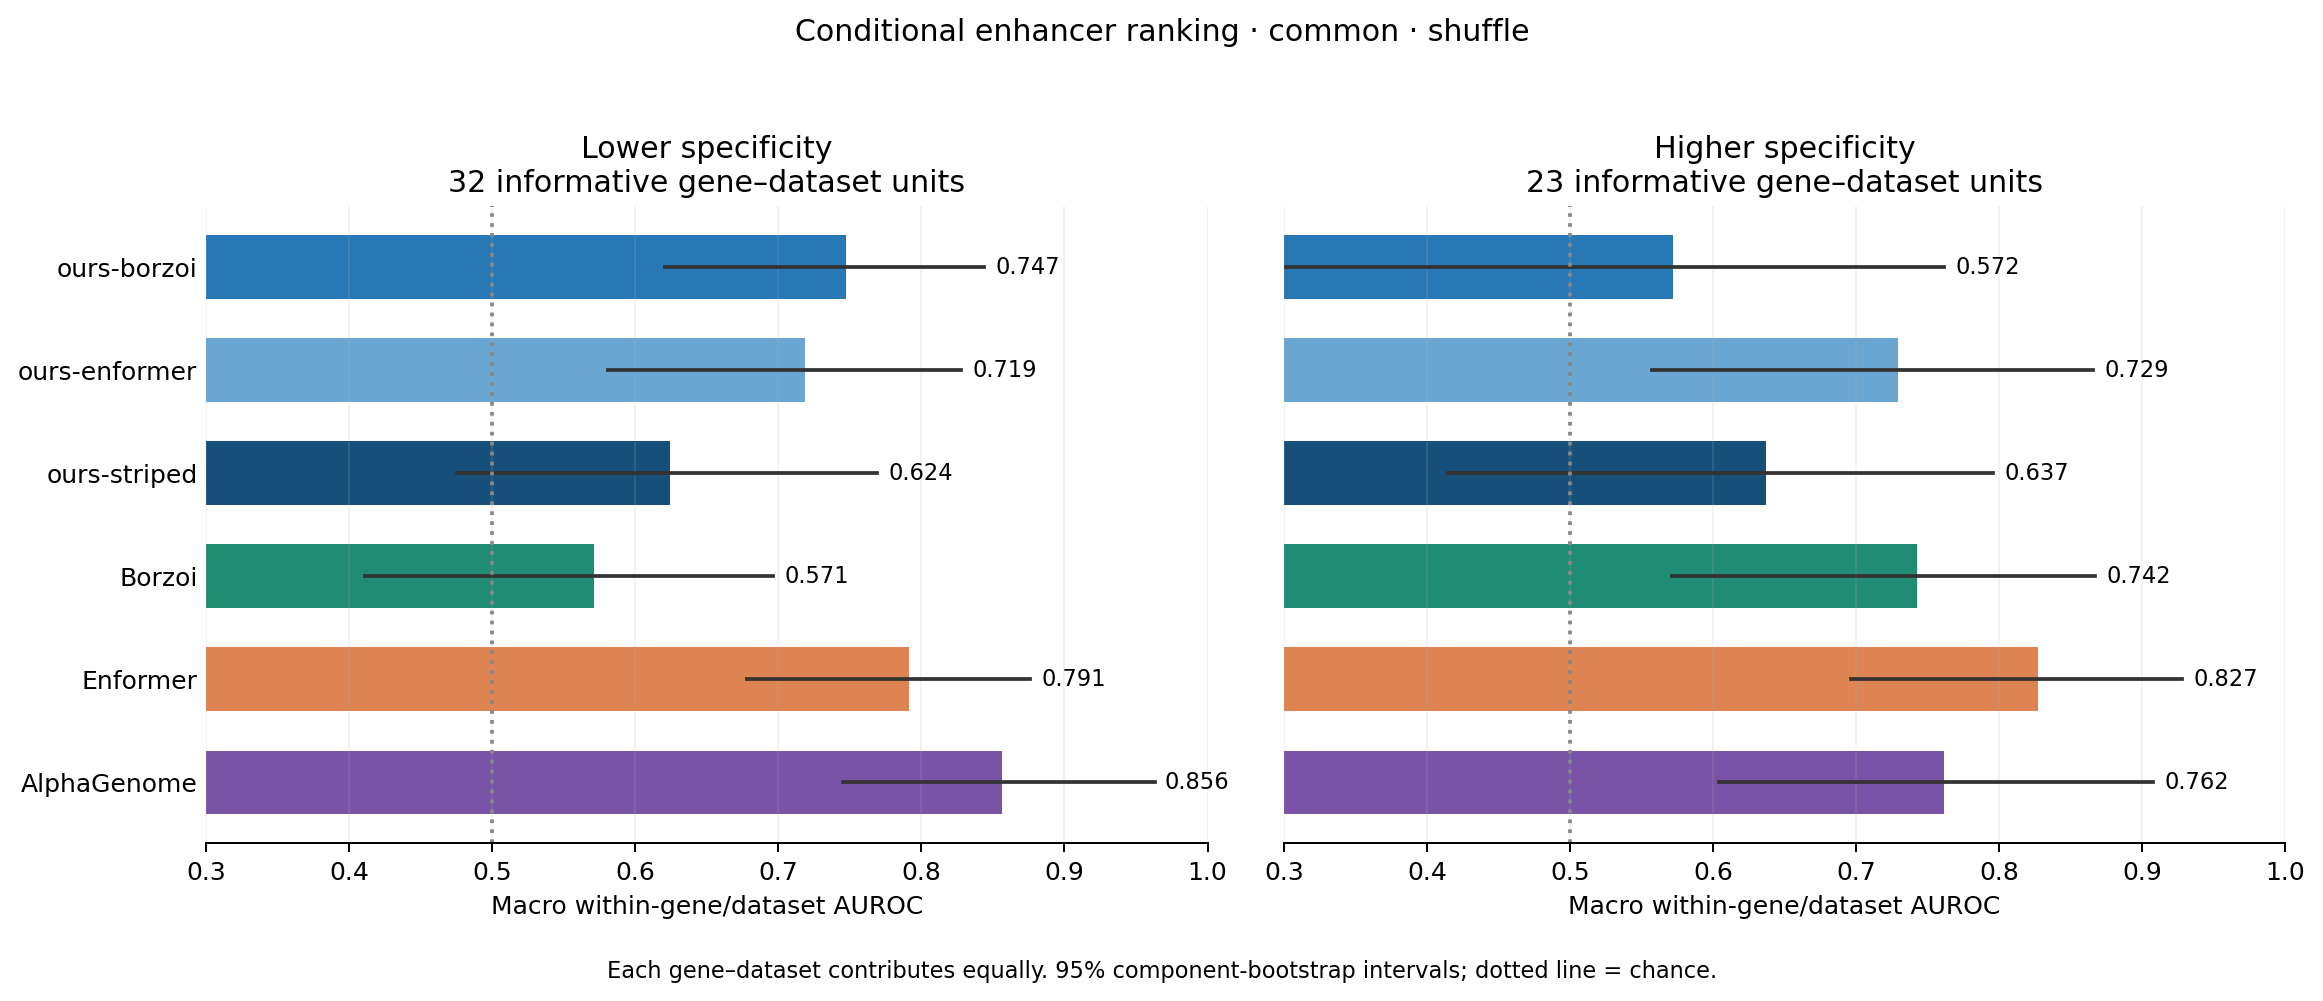

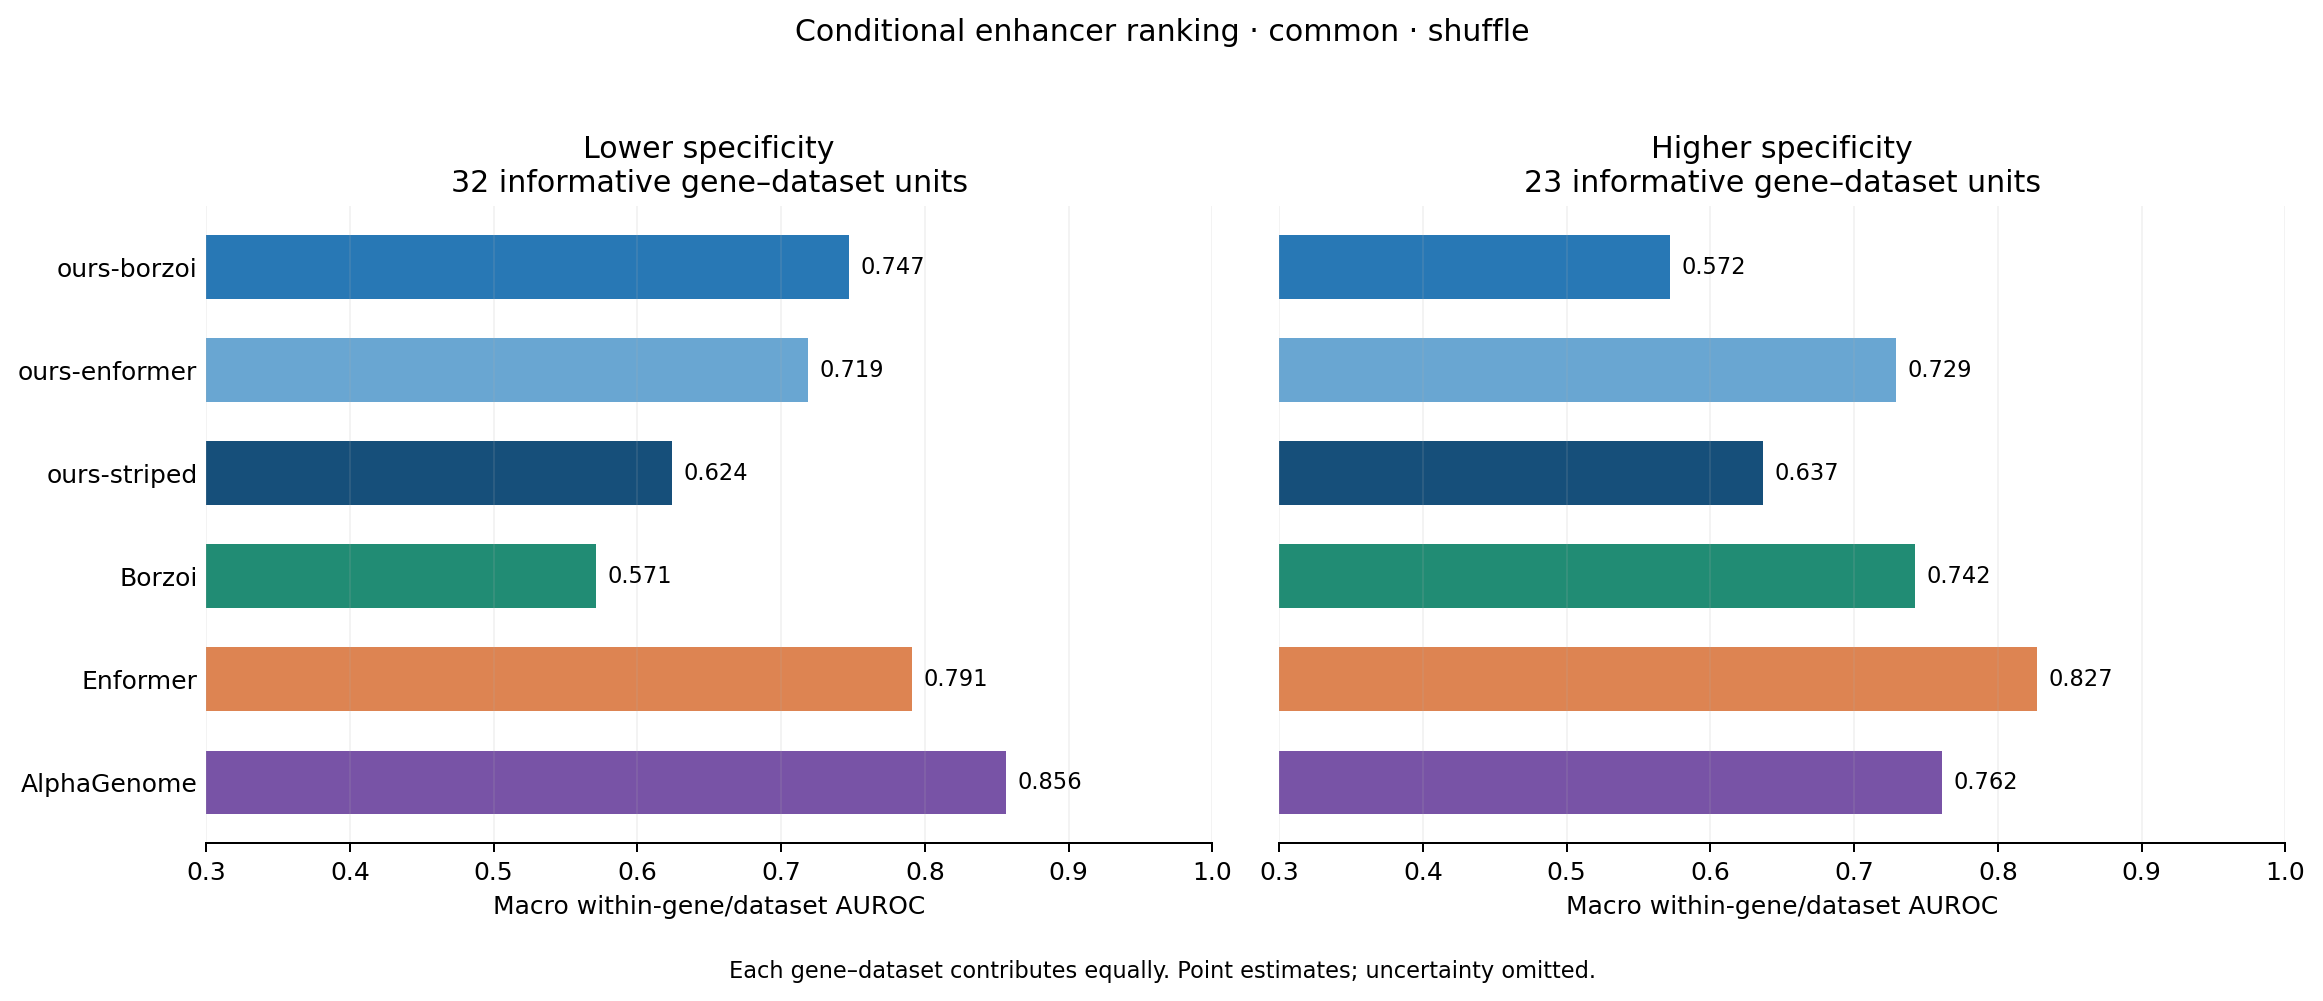

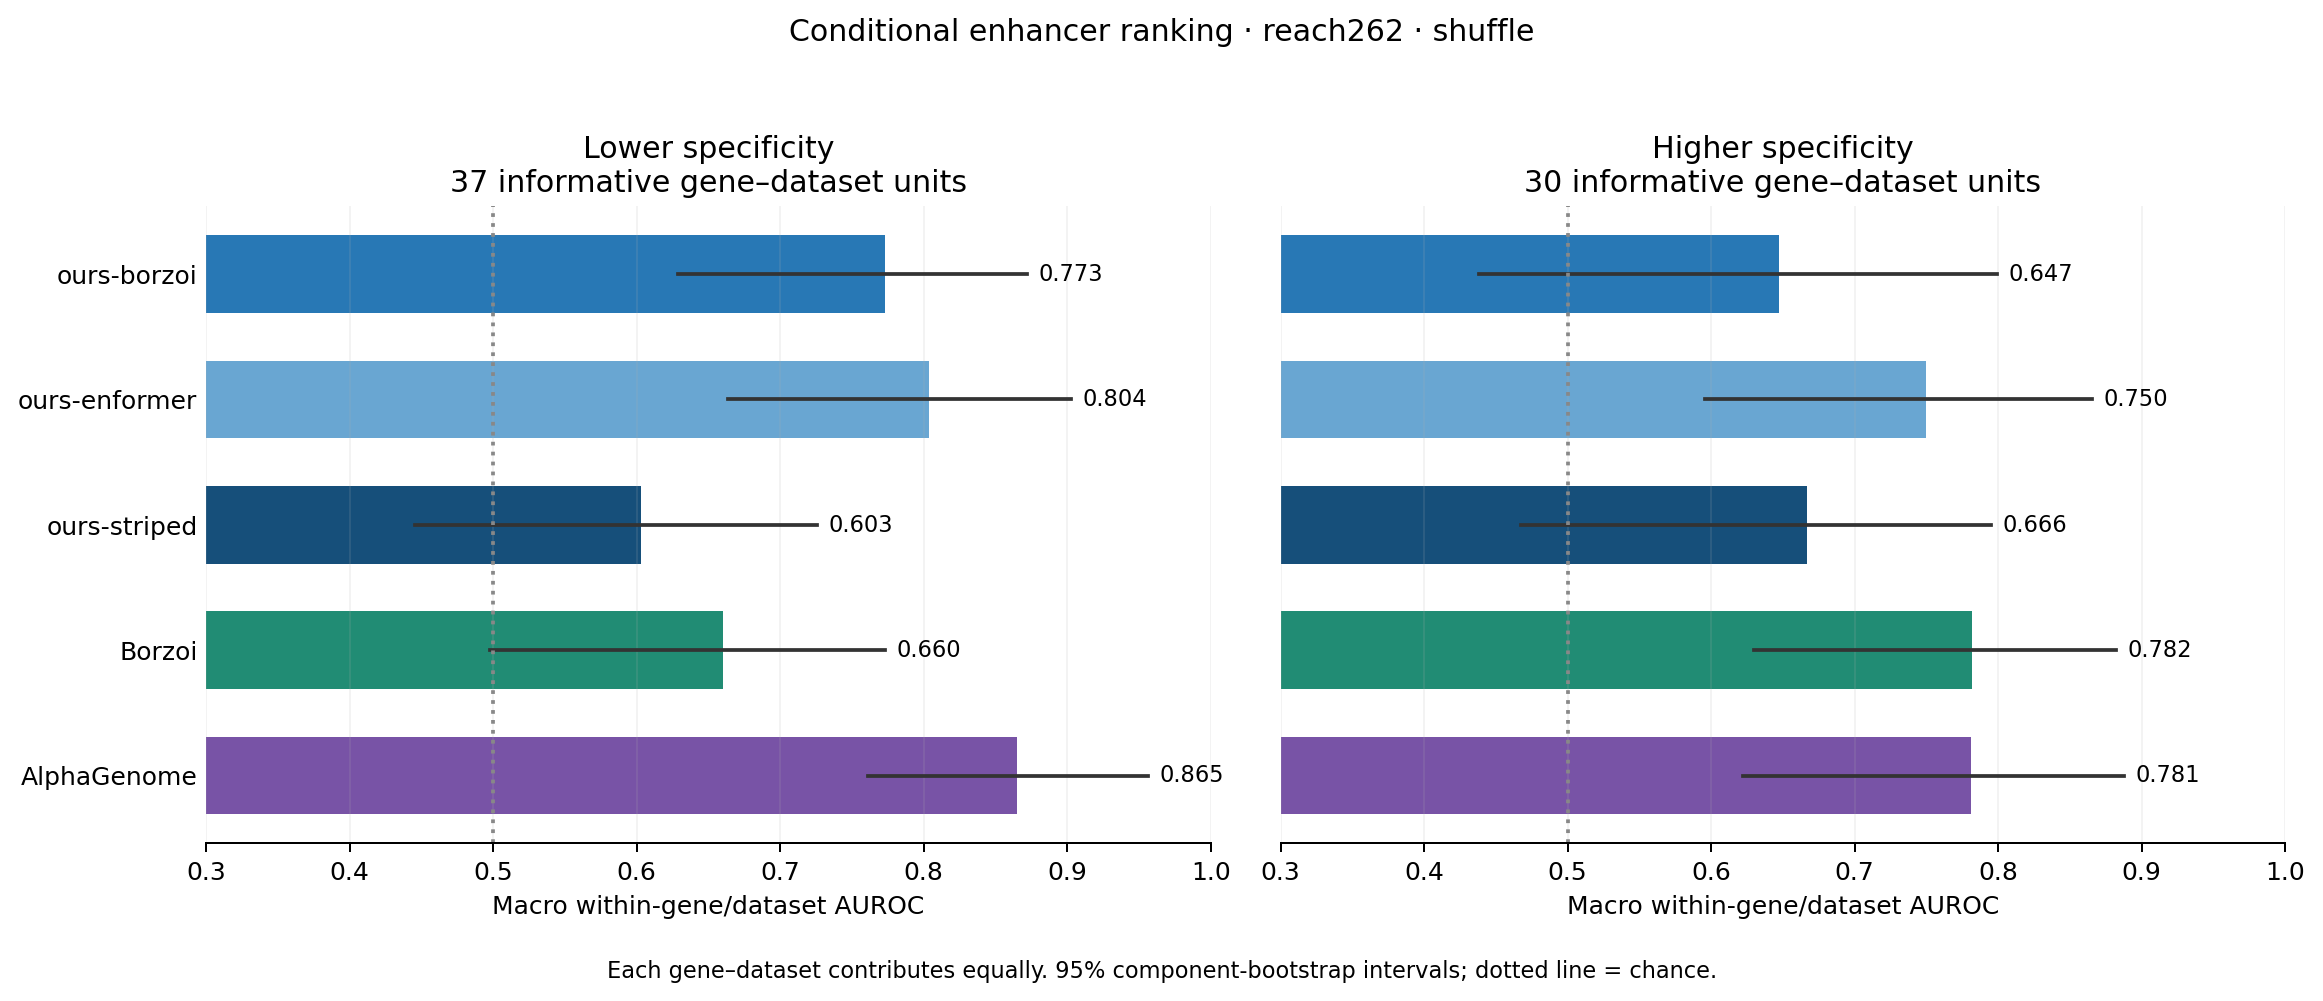

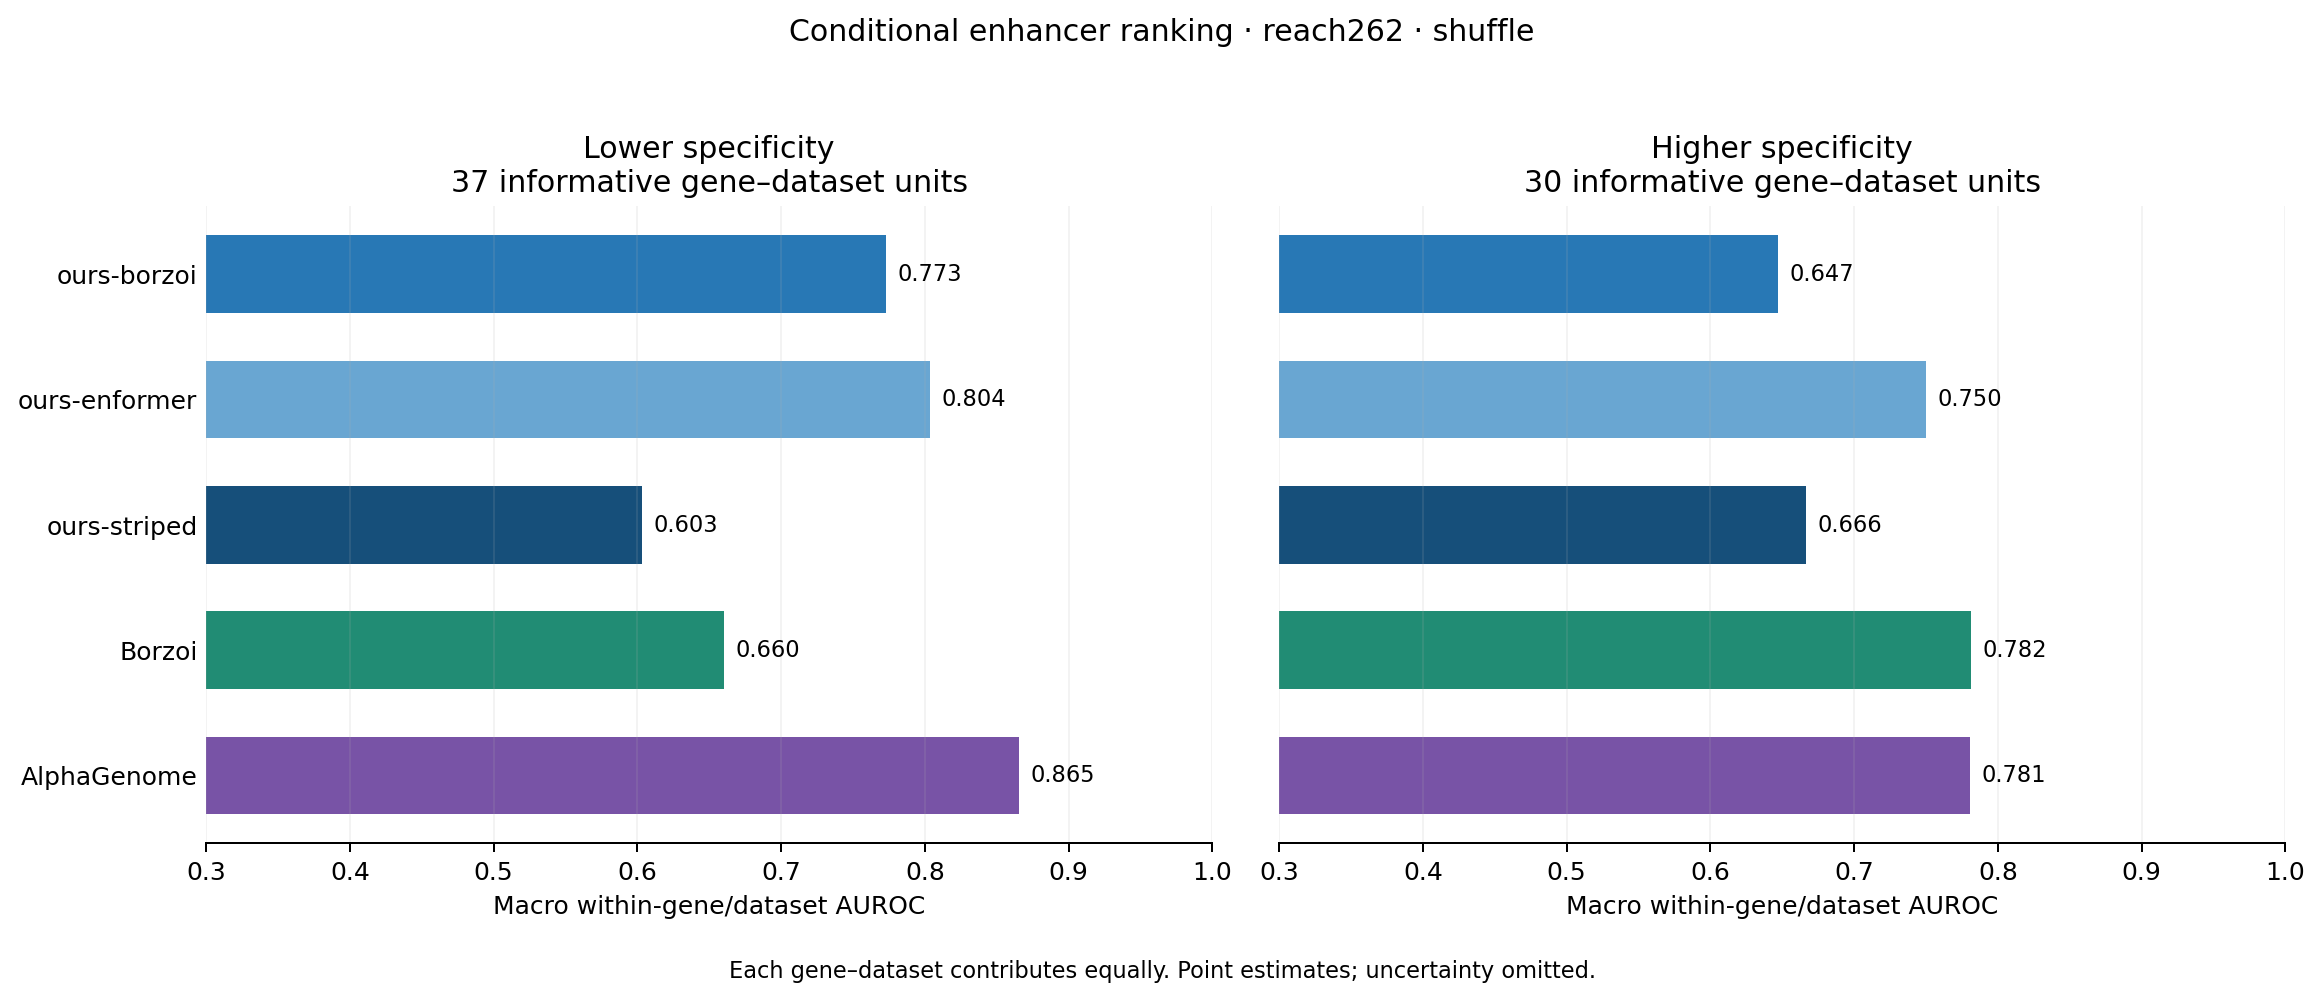

In [13]:
for cohort in cohorts:
    for diagnostic in [True, False]:
        fig = a.plot_within_gene(within_gene, cohort=cohort, arm='shuffle', diagnostic=diagnostic)
        a.plt.close(fig)
        kind='diagnostic' if diagnostic else 'presentation'
        display(Image(filename=str(p.CACHE / 'figures' / f'within_gene_{cohort}_shuffle_{kind}.png')))


## 10. Outputs and reruns

- `ep_linking10_pipeline.py`: exact benchmark mapping, prediction-score cache, overlap-weighted enhancer annotations from cached DNase calls.
- `ep_linking10_analysis.py`: shared cohorts, dependency components, paired bootstrap, diagnostics and plotting.
- First build + notebook: `.pixi/envs/default/bin/python code_test/run_ep_linking10.py all`.
- Fast notebook rerun: `.pixi/envs/default/bin/python code_test/run_ep_linking10.py notebook`.
- Build alone: `... run_ep_linking10.py build`. Completed caches are reused; no model inference or source DNase extraction exists in this pipeline.
- Optional CPU batch: `sbatch code_test/run_ep_linking10.slurm all`; create `code_test/EP_linking10_cache/` before submitting.
- Tests: `.pixi/envs/default/bin/python -m pytest code_test/test_ep_linking10.py`.
- Use a separate `EP10_CACHE` directory for changed input/annotation geometry. Existing source prediction arrays and DNase caches are assumed immutable; manifests record input hashes, source stamps and settings.
- Primary matrices: `track_enhancer_fraction.npy`, `track_enhancer_presence.npy`; rows=`tracks.tsv`, columns=`enhancers.tsv.gz` in `enhancer_index` order. Missing status must accompany binary presence.
- `model_scores.npz`: signed scores plus original context, shuffled completion and valid masks; columns follow `scores_manifest.json`.
- Analysis exports: `pair_scores_and_specificity.tsv.gz`, `cohort_counts.tsv`, `stratified_metrics.tsv`, `paired_model_and_arm_differences.tsv`, `dependency_components.tsv`, `bootstrap_draws.npz`, `distance_diagnostics.tsv`.
- More positive loci may improve precision; current power must be assessed from retained positives and independent components. Do not assume equal positive counts from the median split.
- Gene-expression specificity remains deferred; any future source extraction needs discussion before running it.

- Conditional ranking outputs: `within_gene_unit_AUROC.tsv`, `within_gene_macro_AUROC.tsv`, `within_gene_specificity_differences.tsv`, `within_gene_model_interactions.tsv`, `within_gene_shared_unit_sensitivity.tsv`, and `within_gene_manifest.json`.


In [14]:
print('Output directory:', p.CACHE)
print('Enhancer reference median:', manifest['median'])
print('No original dsQTL/eQTL extraction cache was rebuilt.')


Output directory: /data1/lesliec/sarthak/caduceus/code_test/EP_linking10_cache
Enhancer reference median: 270.0
No original dsQTL/eQTL extraction cache was rebuilt.
